
# 🌦️ METMalaysia Weather API Integration

## Project 01 — Weather Analytics Pipeline Enhancement

### Objective
Integrate the official METMalaysia API V2.1 into a
Python-based data analytics pipeline.

### Research Questions
1. Can the API reliably retrieve Malaysian weather forecasts?
2. What weather variables are available?
3. How can the returned JSON be transformed into
   structured, analysis-ready data?
4. What quality checks are necessary before analysis?

### Scope
- Malaysian general weather forecasts
- API authentication and data retrieval
- JSON processing and data validation
- Exploratory analysis and visualisation

### Important Limitation
Forecasts are predictions, not historical observations.

### Data Source
METMalaysia API V2.1
https://metapi2.met.gov.my/docs



## 🔌 Stage 1 — API Connectivity

### Hypothesis
A correctly authenticated request to METMalaysia's
general forecast endpoint will return structured
JSON containing forecast records for Putrajaya.

### Method
Request the current day's general weather forecast
using the documented location ID.

### Success Criteria
- HTTP status is 200.
- The response contains valid JSON.
- The response includes metadata and results.
- At least one forecast record is returned.

### API Constraints
The API permits a maximum burst of 10 requests per
minute and 2,000 requests per day.

Requests should be limited and repeated calls avoided.


In [9]:

# ============================================================
# METMalaysia API V2.1 — Complete Integration & Debugging
# Project 01: Weather Analytics Pipeline
# ============================================================

import requests
import pandas as pd

from datetime import datetime
from zoneinfo import ZoneInfo
from google.colab import userdata
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — LOAD API TOKEN
# ------------------------------------------------------------

print("STEP 1: Loading API token...")

token = userdata.get("MET_API_TOKEN")

if not token:
    raise ValueError(
        "MET_API_TOKEN is missing. "
        "Add it to Google Colab Secrets."
    )

token = token.strip()

# Avoid accidentally repeating the METToken prefix
if token.startswith("METToken "):
    token = token[len("METToken "):].strip()

if not token:
    raise ValueError("API token is empty.")

BASE_URL = "https://metapi2.met.gov.my/api/v2.1"

headers = {
    "Authorization": f"METToken {token}",
    "Accept": "application/json"
}

print("Token loaded successfully.")
print("Authorization format configured.\n")


# ------------------------------------------------------------
# STEP 2 — DEFINE A REUSABLE API REQUEST FUNCTION
# ------------------------------------------------------------

def call_met_api(endpoint, params=None):
    """
    Send an authenticated GET request to METMalaysia.

    Returns:
        status_code: HTTP response status
        payload: Parsed JSON, or None if unavailable
    """

    url = f"{BASE_URL}/{endpoint.lstrip('/')}"

    try:
        response = requests.get(
            url,
            headers=headers,
            params=params,
            timeout=30
        )

        print(f"Endpoint: /{endpoint.lstrip('/')}")
        print(f"HTTP status: {response.status_code}")

        try:
            payload = response.json()
        except ValueError:
            payload = None

        if response.status_code != 200:
            print("Request unsuccessful.")

            # Never print the token or request headers.
            # Display a limited error message only.
            if isinstance(payload, dict):
                for key in ("detail", "message", "error"):
                    if key in payload:
                        print(
                            f"{key}:",
                            str(payload[key])[:300]
                        )
            else:
                print("No structured JSON error returned.")

        return response.status_code, payload

    except requests.RequestException as error:
        print("Connection error:", type(error).__name__)
        return None, None


# ------------------------------------------------------------
# STEP 3 — TEST API CONNECTIVITY
# ------------------------------------------------------------

print("=" * 55)
print("STEP 3: Testing API connectivity")
print("=" * 55)

datatype_status, datatype_data = call_met_api(
    "datatypes"
)

print()

location_status, location_data = call_met_api(
    "locations",
    params={"locationcategoryid": "STATE"}
)

print()


# ------------------------------------------------------------
# STEP 4 — REQUEST PUTRAJAYA WEATHER FORECAST
# ------------------------------------------------------------

print("=" * 55)
print("STEP 4: Requesting Putrajaya forecast")
print("=" * 55)

today = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).strftime("%Y-%m-%d")

forecast_params = {
    "datasetid": "FORECAST",
    "datacategoryid": "GENERAL",
    "locationid": "LOCATION:237",
    "start_date": today,
    "end_date": today,
    "lang": "en"
}

print("Requested date:", today)
print("Requested location: Putrajaya")

forecast_status, forecast_data = call_met_api(
    "data",
    params=forecast_params
)

print()


# ------------------------------------------------------------
# STEP 5 — VALIDATE AND TRANSFORM FORECAST DATA
# ------------------------------------------------------------

print("=" * 55)
print("STEP 5: Validating forecast data")
print("=" * 55)

forecast_df = pd.DataFrame()

if forecast_status == 200:

    if not isinstance(forecast_data, dict):
        print("Unexpected JSON structure.")

    else:
        metadata = forecast_data.get("metadata", {})
        records = forecast_data.get("results", [])

        print("Metadata:", metadata)

        if isinstance(records, list) and records:

            forecast_df = pd.json_normalize(
                records,
                sep="_"
            )

            print("Records retrieved:", len(forecast_df))
            print("Dataset shape:", forecast_df.shape)

            print("\nAvailable columns:")
            print(forecast_df.columns.tolist())

            print("\nPreview:")
            display(forecast_df.head(10))

            print("\nMissing values:")
            display(
                forecast_df.isna().sum().to_frame(
                    "missing_count"
                )
            )

        else:
            print("No forecast records returned.")

else:
    print(
        "Forecast request unsuccessful. "
        "Data transformation skipped safely."
    )


# ------------------------------------------------------------
# STEP 6 — DIAGNOSTIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("STEP 6: API DIAGNOSTIC SUMMARY")
print("=" * 55)

summary = pd.DataFrame([
    {
        "Endpoint": "/datatypes",
        "HTTP Status": datatype_status
    },
    {
        "Endpoint": "/locations",
        "HTTP Status": location_status
    },
    {
        "Endpoint": "/data (GENERAL forecast)",
        "HTTP Status": forecast_status
    }
])

display(summary)

if forecast_status == 200 and not forecast_df.empty:
    print("SUCCESS: Forecast data retrieved and processed.")

elif forecast_status == 200:
    print("Connected successfully, but no forecast records.")

elif forecast_status == 401:
    print(
        "Forecast returned HTTP 401. "
        "Compare endpoint permissions and authentication."
    )

elif forecast_status == 403:
    print("Forecast access forbidden.")

elif forecast_status == 429:
    print("Rate limit reached. Wait before retrying.")

else:
    print("Review the forecast endpoint status above.")


STEP 1: Loading API token...
Token loaded successfully.
Authorization format configured.

STEP 3: Testing API connectivity
Endpoint: /datatypes
HTTP status: 200

Endpoint: /locations
HTTP status: 200

STEP 4: Requesting Putrajaya forecast
Requested date: 2026-10-19
Requested location: Putrajaya
Endpoint: /data
HTTP status: 200

STEP 5: Validating forecast data
Metadata: {'resultset': {'count': 6, 'offset': 0, 'limit': 50, 'locationid': 'LOCATION:237', 'datasetid': 'FORECAST', 'datacategoryid': 'GENERAL'}}
Records retrieved: 6
Dataset shape: (6, 13)

Available columns:
['locationid', 'locationname', 'locationrootid', 'locationrootname', 'date', 'datatype', 'value', 'latitude', 'longitude', 'attributes_unit', 'attributes_ref', 'attributes_valid_from', 'attributes_valid_to']

Preview:


,locationid,locationname,locationrootid,locationrootname,date,datatype,value,latitude,longitude,attributes_unit,attributes_ref,attributes_valid_from,attributes_valid_to
0,LOCATION:237,Putrajaya,LOCATION:237,Putrajaya,2026-10-19T00:00:00+08:00,FMAXT,33,2.91667,101.7,Celsius,None,None,None
1,LOCATION:237,Putrajaya,LOCATION:237,Putrajaya,2026-10-19T00:00:00+08:00,FMINT,25,2.91667,101.7,Celsius,None,None,None
2,LOCATION:237,Putrajaya,LOCATION:237,Putrajaya,2026-10-19T00:00:00+08:00,FGM,Ribut petir,2.91667,101.7,NaN,None,None,None
3,LOCATION:237,Putrajaya,LOCATION:237,Putrajaya,2026-10-19T00:00:00+08:00,FGA,Ribut petir,2.91667,101.7,NaN,None,None,None
4,LOCATION:237,Putrajaya,LOCATION:237,Putrajaya,2026-10-19T00:00:00+08:00,FGN,Jerebu,2.91667,101.7,NaN,None,None,None
5,LOCATION:237,Putrajaya,LOCATION:237,Putrajaya,2026-10-19T00:00:00+08:00,FSIGW,Thunderstorms,2.91667,101.7,NaN,None,None,None



Missing values:


,missing_count
locationid,0
locationname,0
locationrootid,0
locationrootname,0
date,0
datatype,0
value,0
latitude,0
longitude,0
attributes_unit,4



STEP 6: API DIAGNOSTIC SUMMARY


,Endpoint,HTTP Status
0,/datatypes,200
1,/locations,200
2,/data (GENERAL forecast),200


SUCCESS: Forecast data retrieved and processed.



## 📝 API Integration — Test Results

### Authentication
- Data types endpoint: 200
- Locations endpoint: 200
- General forecast endpoint: 200

### Observations
All three API endpoints returned successful HTTP responses,
indicating that the authentication configuration is valid
for the tested endpoints.

### Technical Interpretation
The results confirm successful authenticated API connectivity.
However, successful HTTP responses do not automatically
guarantee data completeness, accuracy, or suitability for analysis.

### Next Steps
- Resolve any remaining API access errors.
- Inspect the forecast data types.
- Validate the retrieved records.
- Develop exploratory weather visualisations.



## 🔎 Stage 2 — Weather Data Understanding

### Objective
Identify the forecast variables provided by METMalaysia
and determine which are suitable for analysis.

### Hypothesis
The API's data type metadata can be used to interpret
forecast codes and their corresponding measurements.

### Method
1. Extract records from the `/datatypes` response.
2. Convert them into a pandas DataFrame.
3. Inspect variable identifiers and descriptions.
4. Compare them with the general forecast records.

### Analytical Consideration
Not all forecast variables are numeric. Temperature,
weather descriptions, and other categories must be
interpreted according to their documented meaning.


In [10]:

# STEP 1 — Inspect available data types

datatype_records = (
    datatype_data.get("results", [])
    if isinstance(datatype_data, dict)
    else []
)

datatype_df = pd.json_normalize(datatype_records)

print("Available data types:", len(datatype_df))
display(datatype_df.head(20))

# STEP 2 — Inspect forecast variable distribution

if not forecast_df.empty and "datatype" in forecast_df.columns:

    print("\nForecast variables returned:")
    display(
        forecast_df["datatype"]
        .value_counts()
        .rename_axis("datatype")
        .reset_index(name="record_count")
    )

    print("\nSample forecast records:")
    available = [
        col for col in
        ["locationname", "date", "datatype", "value"]
        if col in forecast_df.columns
    ]

    display(forecast_df[available].head(20))

else:
    print("No forecast records available for inspection.")


Available data types: 58


,id,name,datasetid,datacategoryid
0,FGM,FORECAST - GENERAL - DAILY MORNING,FORECAST,GENERAL
1,FGA,FORECAST - GENERAL - DAILY AFTERNOON,FORECAST,GENERAL
2,FGN,FORECAST - GENERAL - DAILY NIGHT,FORECAST,GENERAL
3,FMAXT,FORECAST - GENERAL - DAILY MAXIMUM TEMPERATURE,FORECAST,GENERAL
4,FMINT,FORECAST - GENERAL - DAILY MINIMUM TEMPERATURE,FORECAST,GENERAL
5,FSIGW,FORECAST - GENERAL - DAILY SIGNIFICANT WEATHER,FORECAST,GENERAL
6,WINDSEA,WARNING - STRONG WIND & ROUGH SEA,WARNING,WINDSEA
7,RAIN,WARNING - HEAVY RAIN,WARNING,RAIN
8,CYCLONE,WARNING - TROPICAL CYCLONE,WARNING,CYCLONE
9,QUAKETSUNAMI,ALERT - EARTHQUAKE/TSUNAMI,WARNING,QUAKETSUNAMI



Forecast variables returned:


,datatype,record_count
0,FMAXT,1
1,FMINT,1
2,FGM,1
3,FGA,1
4,FGN,1
5,FSIGW,1



Sample forecast records:


,locationname,date,datatype,value
0,Putrajaya,2026-10-19T00:00:00+08:00,FMAXT,33
1,Putrajaya,2026-10-19T00:00:00+08:00,FMINT,25
2,Putrajaya,2026-10-19T00:00:00+08:00,FGM,Ribut petir
3,Putrajaya,2026-10-19T00:00:00+08:00,FGA,Ribut petir
4,Putrajaya,2026-10-19T00:00:00+08:00,FGN,Jerebu
5,Putrajaya,2026-10-19T00:00:00+08:00,FSIGW,Thunderstorms



## 🧹 Stage 3 — Data Transformation and Validation

### Objective
Transform the API's long-format forecast records into a
structured dataset containing one row per location and date.

### Hypothesis
Each weather datatype represents a different forecast
attribute for the same location and date.

### Methodology
1. Validate required columns.
2. Check duplicate location-date-datatype combinations.
3. Reshape records from long format into wide format.
4. Convert temperature variables to numeric values.
5. Check temperature consistency.
6. Preserve weather descriptions as categorical values.

### Limitations
Passing data quality checks does not establish forecast
accuracy. Accuracy requires comparison with actual
observed weather data.


In [11]:

# ============================================================
# STAGE 3 — FORECAST TRANSFORMATION AND VALIDATION
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Confirm the necessary columns exist
required_columns = [
    "locationid",
    "locationname",
    "date",
    "datatype",
    "value"
]

missing_columns = [
    col for col in required_columns
    if col not in forecast_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

if forecast_df.empty:
    raise ValueError("No forecast records available.")

# 2. Work on a copy of the original API data
clean_df = forecast_df.copy()

# 3. Convert dates
clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    errors="coerce"
)

if clean_df["date"].isna().any():
    raise ValueError("Invalid forecast dates detected.")

# 4. Check duplicates before reshaping
keys = ["locationid", "date", "datatype"]

duplicate_count = clean_df.duplicated(
    subset=keys
).sum()

print("Duplicate forecast records:", duplicate_count)

if duplicate_count > 0:
    raise ValueError(
        "Duplicate forecast variables detected. "
        "Inspect before reshaping."
    )

# 5. Reshape long-format records into wide format
daily_forecast = (
    clean_df.pivot(
        index=["locationid", "locationname", "date"],
        columns="datatype",
        values="value"
    )
    .reset_index()
)

daily_forecast.columns.name = None

# 6. Convert temperatures to numeric
temperature_columns = ["FMAXT", "FMINT"]

for col in temperature_columns:
    if col not in daily_forecast.columns:
        daily_forecast[col] = pd.NA

    daily_forecast[col] = pd.to_numeric(
        daily_forecast[col],
        errors="coerce"
    )

# 7. Validate temperature consistency
valid_temps = daily_forecast[
    ["FMAXT", "FMINT"]
].notna().all(axis=1)

invalid_order = (
    valid_temps
    & (daily_forecast["FMAXT"] < daily_forecast["FMINT"])
)

print("Rows missing temperature data:",
      (~valid_temps).sum())

print("Rows with max temperature below min:",
      invalid_order.sum())

# 8. Calculate temperature spread only for valid rows
daily_forecast["temperature_spread_c"] = (
    daily_forecast["FMAXT"] - daily_forecast["FMINT"]
)

daily_forecast.loc[
    ~valid_temps | invalid_order,
    "temperature_spread_c"
] = float("nan")

# 9. Display the transformed dataset
print("\nTransformed dataset shape:",
      daily_forecast.shape)

display(daily_forecast)


Duplicate forecast records: 0
Rows missing temperature data: 0
Rows with max temperature below min: 0

Transformed dataset shape: (1, 10)


,locationid,locationname,date,FGA,FGM,FGN,FMAXT,FMINT,FSIGW,temperature_spread_c
0,LOCATION:237,Putrajaya,2026-10-19 00:00:00+08:00,Ribut petir,Ribut petir,Jerebu,33,25,Thunderstorms,8.0



## 📝 Stage 3 — Conclusion

The METMalaysia forecast records were successfully
transformed from long format into a structured daily
forecast dataset.

### Validation Results
- Duplicate location-date-datatype records: 0
- Rows missing temperature values: 0
- Invalid maximum/minimum temperature order: 0
- Final dataset shape: 1 row × 10 columns

### Key Findings
For Putrajaya on 19 October 2026:
- Forecast maximum temperature: 33°C
- Forecast minimum temperature: 25°C
- Forecast temperature spread: 8°C
- Morning and afternoon: Thunderstorm conditions
- Night: Haze

### Analytical Limitations
The dataset contains only one location and one
forecast date.

Therefore, it is insufficient for trend analysis,
seasonality analysis, or statistical comparisons
between locations.

The validation checks confirm structural consistency,
not forecast accuracy.

### Next Step
Expand the dataset across multiple forecast dates
before developing time-series visualisations.



## 📅 Stage 4 — Multi-Day Forecast Collection

### Research Question
How do forecast temperatures and weather conditions
vary across the available forecast period in Putrajaya?

### Hypothesis
Forecast maximum and minimum temperatures may vary
across the requested dates.

### Method
Request a seven-calendar-day forecast window using
the documented start_date and end_date parameters.

### Validation
- Verify the number of distinct dates returned.
- Check whether all requested dates are available.
- Inspect forecast variables and missing values.

### Limitation
Requesting seven dates does not guarantee that
METMalaysia publishes forecasts for all seven dates.


In [12]:

# ============================================================
# STAGE 4 — MULTI-DAY FORECAST RETRIEVAL
# ============================================================

import pandas as pd
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo
from IPython.display import display

# Malaysian local dates
start_date = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).date()

end_date = start_date + timedelta(days=6)

multi_day_params = {
    "datasetid": "FORECAST",
    "datacategoryid": "GENERAL",
    "locationid": "LOCATION:237",
    "start_date": start_date.isoformat(),
    "end_date": end_date.isoformat(),
    "lang": "en"
}

print("Requested start date:", start_date)
print("Requested end date:", end_date)

multi_status, multi_payload = call_met_api(
    "data",
    params=multi_day_params
)

multi_forecast_df = pd.DataFrame()

if multi_status == 200 and isinstance(multi_payload, dict):

    records = multi_payload.get("results", [])

    if isinstance(records, list) and records:
        multi_forecast_df = pd.json_normalize(
            records,
            sep="_"
        )

        multi_forecast_df["date"] = pd.to_datetime(
            multi_forecast_df["date"],
            errors="coerce"
        )

        print("\nTotal records:", len(multi_forecast_df))
        print("Distinct dates:",
              multi_forecast_df["date"].nunique())

        print("\nForecast dates returned:")
        display(
            multi_forecast_df["date"]
            .dt.date
            .drop_duplicates()
            .sort_values()
            .reset_index(drop=True)
        )

        print("\nRecords by date:")
        display(
            multi_forecast_df.groupby(
                multi_forecast_df["date"].dt.date
            ).size().to_frame("record_count")
        )

    else:
        print("No forecast records returned.")

else:
    print("Multi-day request unsuccessful.")


Requested start date: 2026-10-19
Requested end date: 2026-10-25
Endpoint: /data
HTTP status: 200

Total records: 42
Distinct dates: 7

Forecast dates returned:


,date
0,2026-10-19
1,2026-10-20
2,2026-10-21
3,2026-10-22
4,2026-10-23
5,2026-10-24
6,2026-10-25



Records by date:


,record_count
date,
2026-10-19,6
2026-10-20,6
2026-10-21,6
2026-10-22,6
2026-10-23,6
2026-10-24,6
2026-10-25,6



## 📝 Stage 4 — Conclusion

### Results
- API response: HTTP 200
- Requested period: 19–25 October 2026
- Total forecast records: 42
- Distinct forecast dates: 7

### Interpretation
The API successfully returned forecasts covering all
seven requested dates.

The response contains an average of six forecast
records per date, consistent with the expected six
forecast variables.

### Limitations
- Forecast values are predictions, not observations.
- Seven days are insufficient for seasonality analysis.
- Forecast completeness must be checked at the
  individual datatype level.

### Next Step
Validate datatype coverage, transform the multi-day
records, and examine temperature variation.



## 🧹 Stage 5 — Multi-Day Data Preparation

### Objective
Prepare a validated seven-day forecast dataset
for temperature and weather-condition analysis.

### Hypothesis
Each forecast date contains one record for each
of the six expected forecast variables.

### Method
1. Check required fields and forecast dates.
2. Validate duplicate records.
3. Verify datatype completeness for each date.
4. Reshape the data into daily records.
5. Convert temperatures to numeric values.
6. Calculate daily forecast temperature spread.

### Quality Criteria
- Seven distinct forecast dates.
- Six expected datatypes per date.
- No duplicate location-date-datatype combinations.
- Maximum temperature is not below minimum temperature.


In [13]:

# ============================================================
# STAGE 5 — MULTI-DAY FORECAST VALIDATION
# ============================================================

import pandas as pd
from IPython.display import display

expected_types = {
    "FMAXT", "FMINT", "FGM",
    "FGA", "FGN", "FSIGW"
}

required = {
    "locationid", "locationname",
    "date", "datatype", "value"
}

missing = required - set(multi_forecast_df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

if multi_forecast_df.empty:
    raise ValueError("Forecast dataset is empty.")

work_df = multi_forecast_df.copy()

# Convert dates while preserving the forecast day
work_df["date"] = pd.to_datetime(
    work_df["date"],
    errors="coerce"
).dt.date

if work_df["date"].isna().any():
    raise ValueError("Invalid forecast dates found.")

# 1. Check duplicates
keys = ["locationid", "date", "datatype"]

duplicate_count = work_df.duplicated(
    subset=keys
).sum()

print("Duplicate records:", duplicate_count)

if duplicate_count:
    raise ValueError(
        "Duplicate forecast variables detected."
    )

# 2. Check datatype coverage by date
coverage = pd.crosstab(
    work_df["date"],
    work_df["datatype"]
)

print("\nDatatype coverage by date:")
display(coverage)

# 3. Check missing expected variables
coverage_issues = {}

for forecast_date, group in work_df.groupby("date"):
    present = set(group["datatype"])
    missing_types = expected_types - present
    unexpected_types = present - expected_types

    if missing_types or unexpected_types:
        coverage_issues[str(forecast_date)] = {
            "missing": sorted(missing_types),
            "unexpected": sorted(unexpected_types)
        }

print("\nCoverage issues:", coverage_issues)

# 4. Reshape to daily records
daily_df = (
    work_df.pivot(
        index=["locationid", "locationname", "date"],
        columns="datatype",
        values="value"
    )
    .reset_index()
)

daily_df.columns.name = None

# 5. Convert temperatures to numeric
for col in ["FMAXT", "FMINT"]:
    if col not in daily_df.columns:
        daily_df[col] = pd.NA

    daily_df[col] = pd.to_numeric(
        daily_df[col],
        errors="coerce"
    )

# 6. Validate temperature order
invalid_temp = (
    daily_df["FMAXT"].notna()
    & daily_df["FMINT"].notna()
    & (daily_df["FMAXT"] < daily_df["FMINT"])
)

# 7. Calculate forecast temperature spread
daily_df["temperature_spread_c"] = (
    daily_df["FMAXT"] - daily_df["FMINT"]
)

daily_df.loc[
    invalid_temp, "temperature_spread_c"
] = float("nan")

# 8. Sort chronologically
daily_df = daily_df.sort_values(
    ["locationname", "date"]
).reset_index(drop=True)

print("\nInvalid temperature rows:",
      invalid_temp.sum())

print("Missing temperature values:")
print(daily_df[["FMAXT", "FMINT"]].isna().sum())

print("\nFinal dataset shape:", daily_df.shape)

display(daily_df)


Duplicate records: 0

Datatype coverage by date:


datatype,FGA,FGM,FGN,FMAXT,FMINT,FSIGW
date,,,,,,
2026-10-19,1,1,1,1,1,1
2026-10-20,1,1,1,1,1,1
2026-10-21,1,1,1,1,1,1
2026-10-22,1,1,1,1,1,1
2026-10-23,1,1,1,1,1,1
2026-10-24,1,1,1,1,1,1
2026-10-25,1,1,1,1,1,1



Coverage issues: {}

Invalid temperature rows: 0
Missing temperature values:
FMAXT    0
FMINT    0
dtype: int64

Final dataset shape: (7, 10)


,locationid,locationname,date,FGA,FGM,FGN,FMAXT,FMINT,FSIGW,temperature_spread_c
0,LOCATION:237,Putrajaya,2026-10-19,Ribut petir,Ribut petir,Jerebu,33,25,Thunderstorms,8.0
1,LOCATION:237,Putrajaya,2026-10-20,Jerebu,Hujan,Jerebu,33,25,Rain,8.0
2,LOCATION:237,Putrajaya,2026-10-21,Jerebu,Jerebu,Jerebu,33,25,Haze,8.0
3,LOCATION:237,Putrajaya,2026-10-22,Jerebu,Jerebu,Jerebu,33,25,Haze,8.0
4,LOCATION:237,Putrajaya,2026-10-23,Jerebu,Jerebu,Jerebu,33,25,Haze,8.0
5,LOCATION:237,Putrajaya,2026-10-24,Ribut petir,Tiada Hujan,Tiada Hujan,33,25,Thunderstorms,8.0
6,LOCATION:237,Putrajaya,2026-10-25,Ribut petir,Tiada Hujan,Tiada Hujan,33,25,Thunderstorms,8.0



## 📝 Stage 5 — Conclusion

### Validation Results
- Seven forecast dates successfully processed.
- Six expected datatypes available per date.
- No duplicate records.
- No missing maximum or minimum temperatures.
- No invalid maximum/minimum temperature combinations.
- Final dataset: 7 rows × 10 columns.

### Key Findings
Putrajaya's forecast maximum and minimum temperatures
remain constant at 33°C and 25°C throughout the
seven-day forecast period.

However, the categorical weather conditions vary
between days.

### Critical Interpretation
The constant temperature forecasts should not be
interpreted as proof that actual temperatures will
remain unchanged.

The dataset represents forecast estimates, not
measured weather observations.

### Next Step
Explore temperature stability and categorical weather
conditions using descriptive visualisations.



## 📊 Stage 6 — Exploratory Data Analysis

### Research Questions
1. Do forecast maximum and minimum temperatures vary
   across the seven-day period?
2. Which significant-weather categories appear most
   frequently in the forecasts?

### Hypotheses
H1: Forecast temperatures may vary across dates.

H2: Certain significant-weather categories may appear
more frequently than others.

### Method
- Plot daily forecast maximum and minimum temperatures.
- Count significant-weather categories.
- Visualise category frequencies.

### Limitation
The charts describe one seven-day forecast snapshot
for Putrajaya, not observed weather patterns.


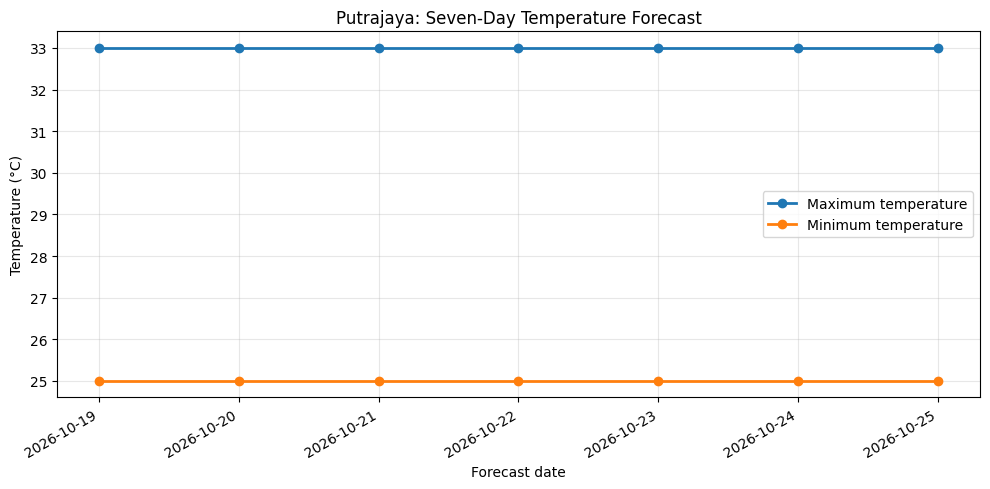

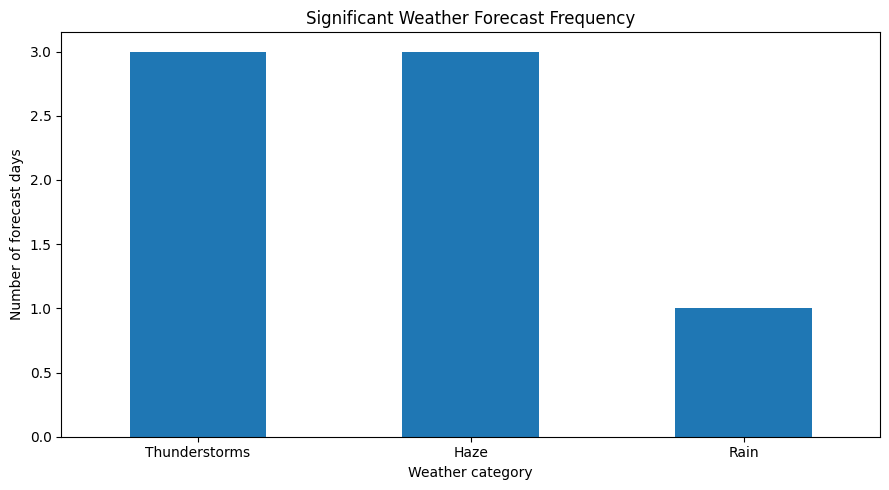

Temperature summary:


,FMAXT,FMINT,temperature_spread_c
count,7.0,7.0,7.0
mean,33.0,25.0,8.0
std,0.0,0.0,0.0
min,33.0,25.0,8.0
25%,33.0,25.0,8.0
50%,33.0,25.0,8.0
75%,33.0,25.0,8.0
max,33.0,25.0,8.0



Significant weather frequency:


,forecast_days
FSIGW,
Thunderstorms,3
Haze,3
Rain,1


In [14]:

# ============================================================
# STAGE 6 — EXPLORATORY DATA ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Work on a copy
eda_df = daily_df.copy()

eda_df["date"] = pd.to_datetime(eda_df["date"])

# ------------------------------------------------------------
# CHART 1 — DAILY FORECAST TEMPERATURES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    eda_df["date"],
    eda_df["FMAXT"],
    marker="o",
    linewidth=2,
    label="Maximum temperature"
)

ax.plot(
    eda_df["date"],
    eda_df["FMINT"],
    marker="o",
    linewidth=2,
    label="Minimum temperature"
)

ax.set_title("Putrajaya: Seven-Day Temperature Forecast")
ax.set_xlabel("Forecast date")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# CHART 2 — SIGNIFICANT WEATHER FREQUENCY
# ------------------------------------------------------------

weather_counts = (
    eda_df["FSIGW"]
    .fillna("Unknown")
    .value_counts()
)

fig, ax = plt.subplots(figsize=(9, 5))

weather_counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Significant Weather Forecast Frequency")
ax.set_xlabel("Weather category")
ax.set_ylabel("Number of forecast days")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SUMMARY STATISTICS
# ------------------------------------------------------------

print("Temperature summary:")
display(
    eda_df[["FMAXT", "FMINT", "temperature_spread_c"]]
    .describe()
)

print("\nSignificant weather frequency:")
display(weather_counts.to_frame("forecast_days"))



## 📝 Stage 6 — Exploratory Analysis Conclusion

### Temperature Analysis
Across the seven-day forecast period (19–25 October 2026),
Putrajaya's forecast maximum temperature remained at
33°C and minimum temperature at 25°C.

Both temperature variables had a standard deviation
of 0°C, indicating no variation in the retrieved
forecast values.

### Significant Weather Analysis
- Thunderstorms: 3 forecast dates
- Haze: 3 forecast dates
- Rain: 1 forecast date

Thunderstorms and haze were the most frequently
represented significant-weather categories.

### Critical Interpretation
The forecast temperatures remained constant while
the categorical weather descriptions varied.

This demonstrates that temperature forecasts alone
do not capture every aspect of the weather outlook.

### Limitations
- Data covers one location and seven forecast dates.
- The dataset is a forecast snapshot, not historical
  weather observations.
- No observed weather data was used to assess accuracy.
- Forecast categories represent published outlooks,
  not confirmed weather events.

### Next Step
Export validated datasets, visualisations, and a
summary report with retrieval metadata.



## 🇲🇾 Stage 7A — Malaysia-Wide Forecast Discovery

### Objective
Determine whether METMalaysia API V2.1 can provide
general weather forecasts for multiple Malaysian locations.

### Hypothesis
Using ALL_LOCATIONS will return forecast records
covering multiple Malaysian geographic locations.

### Method
1. Request one day of general forecast data.
2. Inspect response metadata and record counts.
3. Identify distinct locations.
4. Assess whether pagination or geographic filtering
   is required.

### Analytical Consideration
State, district, town, and tourist-destination forecasts
must not be treated as equivalent geographic units.

### Limitation
A successful API request does not guarantee complete
national coverage in a single response.


In [15]:

# ============================================================
# STAGE 7A — MALAYSIA-WIDE FORECAST DISCOVERY
# ============================================================

import pandas as pd
from datetime import datetime
from zoneinfo import ZoneInfo
from IPython.display import display

today = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).date().isoformat()

malaysia_params = {
    "datasetid": "FORECAST",
    "datacategoryid": "GENERAL",
    "locationid": "ALL_LOCATIONS",
    "start_date": today,
    "end_date": today,
    "lang": "en"
}

print("Requesting Malaysia-wide forecast sample...")
print("Date:", today)

malaysia_status, malaysia_payload = call_met_api(
    "data",
    params=malaysia_params
)

malaysia_df = pd.DataFrame()

if malaysia_status == 200 and isinstance(
    malaysia_payload, dict
):
    metadata = malaysia_payload.get("metadata", {})
    records = malaysia_payload.get("results", [])

    print("\nResponse metadata:")
    print(metadata)

    if isinstance(records, list) and records:
        malaysia_df = pd.json_normalize(
            records,
            sep="_"
        )

        print("\nRecords in response:", len(malaysia_df))

        if "locationid" in malaysia_df.columns:
            print(
                "Distinct locations:",
                malaysia_df["locationid"].nunique()
            )

        print("\nSample locations:")
        available = [
            col for col in [
                "locationid",
                "locationname",
                "date",
                "datatype",
                "value"
            ]
            if col in malaysia_df.columns
        ]

        display(malaysia_df[available].head(15))

    else:
        print("No forecast records returned.")

else:
    print("Request unsuccessful or unexpected response.")


Requesting Malaysia-wide forecast sample...
Date: 2026-10-19
Endpoint: /data
HTTP status: 200

Response metadata:
{'resultset': {'count': 300, 'offset': 0, 'limit': 50, 'locationid': 'ALL_LOCATIONS', 'datasetid': 'FORECAST', 'datacategoryid': 'GENERAL'}}

Records in response: 300
Distinct locations: 50

Sample locations:


,locationid,locationname,date,datatype,value
0,M1500,Linggi,2026-10-19T00:00:00+08:00,FMAXT,32
1,M1500,Linggi,2026-10-19T00:00:00+08:00,FMINT,24
2,M1500,Linggi,2026-10-19T00:00:00+08:00,FGM,Ribut petir
3,M1500,Linggi,2026-10-19T00:00:00+08:00,FGA,Ribut petir
4,M1500,Linggi,2026-10-19T00:00:00+08:00,FGN,Jerebu
5,M1500,Linggi,2026-10-19T00:00:00+08:00,FSIGW,Thunderstorms
6,M0850,Bandar Gopeng,2026-10-19T00:00:00+08:00,FMAXT,34
7,M0850,Bandar Gopeng,2026-10-19T00:00:00+08:00,FMINT,24
8,M0850,Bandar Gopeng,2026-10-19T00:00:00+08:00,FGM,Tiada Hujan
9,M0850,Bandar Gopeng,2026-10-19T00:00:00+08:00,FGA,Ribut petir



## 🇲🇾 Stage 7B — API Pagination Verification

### Objective
Determine whether the ALL_LOCATIONS endpoint supports
retrieving additional forecast locations using offset.

### Hypothesis
Setting offset=50 will return a different set of
locations from the initial API response.

### Method
1. Request the same forecast date.
2. Set offset to 50.
3. Compare the returned location IDs with the first page.
4. Check whether the pages overlap.

### Success Criteria
- HTTP 200 response.
- Additional forecast locations returned.
- No overlapping location IDs between pages.

### Limitation
Successful pagination does not automatically establish
complete coverage of every Malaysian state or district.


In [16]:

# ============================================================
# STAGE 7B — PAGINATION TEST
# ============================================================

import pandas as pd
from IPython.display import display

# Copy the working request parameters
page_2_params = malaysia_params.copy()

# Request the next page
page_2_params["offset"] = 50

page_2_status, page_2_payload = call_met_api(
    "data",
    params=page_2_params
)

page_2_df = pd.DataFrame()

if page_2_status == 200 and isinstance(
    page_2_payload, dict
):
    page_2_records = page_2_payload.get("results", [])

    page_2_df = pd.json_normalize(
        page_2_records,
        sep="_"
    )

    print("\nPage 2 metadata:")
    print(page_2_payload.get("metadata", {}))

    if not page_2_df.empty:

        page_1_locations = set(
            malaysia_df["locationid"].dropna()
        )

        page_2_locations = set(
            page_2_df["locationid"].dropna()
        )

        overlapping = (
            page_1_locations & page_2_locations
        )

        print("\nPage 1 locations:", len(page_1_locations))
        print("Page 2 locations:", len(page_2_locations))
        print("Overlapping locations:", len(overlapping))

        print("\nSample new locations:")
        display(
            page_2_df[
                ["locationid", "locationname"]
            ]
            .drop_duplicates()
            .head(15)
        )

    else:
        print("Page 2 returned no records.")

else:
    print("Page 2 request unsuccessful.")


Endpoint: /data
HTTP status: 200

Page 2 metadata:
{'resultset': {'count': 300, 'offset': 50, 'limit': 50, 'locationid': 'ALL_LOCATIONS', 'datasetid': 'FORECAST', 'datacategoryid': 'GENERAL'}}

Page 1 locations: 50
Page 2 locations: 50
Overlapping locations: 0

Sample new locations:


,locationid,locationname
0,LOCATION:319,Lumut
6,M0942,Lekir
12,M0890,Sitiawan
18,M0857,Beruas
24,M0873,Pekan Segari
30,M0920,Lumut
36,LOCATION:226,Sitiawan
42,M0907,Pekan Sungai Pinang Kechil
48,M0912,Pekan Pasir Bogak
54,M0896,Pekan Kampong Sitiawan



## 📝 Stage 7B — Pagination Verification

### Results
- First page: 50 distinct locations
- Second page: 50 distinct locations
- Overlapping location IDs: 0
- Second page offset: 50

### Interpretation
The API successfully returned a second set of
forecast locations without overlapping the first page.

This confirms that pagination can be used to retrieve
additional Malaysian forecast locations.

### Limitation
Two successful pages do not establish complete
national coverage. The full dataset must be retrieved
and checked before making nationwide claims.



## 🇲🇾 Stage 7C — Malaysia-Wide Forecast Collection

### Objective
Retrieve general weather forecasts for all locations
available through the METMalaysia API.

### Methodology
1. Request forecast data using ALL_LOCATIONS.
2. Retrieve additional pages using offset.
3. Respect the API's request limits.
4. Combine the returned records.
5. Check duplicate location-date-datatype combinations.
6. Assess geographic coverage.

### Hypothesis
Pagination will allow the pipeline to retrieve
more forecast locations than a single API request.

### Limitations
- API coverage may not include every Malaysian locality.
- Geographic categories may differ between locations.
- API results may change between requests.
- The returned data represents forecasts, not observations.


In [17]:

# ============================================================
# STAGE 7C — MALAYSIA-WIDE FORECAST COLLECTION
# ============================================================

import time
import pandas as pd
from IPython.display import display

PAGE_SIZE = 50
MAX_PAGES = 20
REQUEST_DELAY = 7  # seconds; below 10 requests/minute

all_records = []
seen_locations = set()
collection_complete = False

for page_number in range(MAX_PAGES):

    offset = page_number * PAGE_SIZE

    params = malaysia_params.copy()
    params["offset"] = offset

    print(f"\nFetching page {page_number + 1}")
    print(f"Offset: {offset}")

    status, payload = call_met_api(
        "data",
        params=params
    )

    if status != 200 or not isinstance(payload, dict):
        print("Stopping due to API error.")
        break

    records = payload.get("results", [])

    if not isinstance(records, list):
        print("Unexpected results format.")
        break

    if not records:
        print("No more records.")
        collection_complete = True
        break

    page_df = pd.json_normalize(records)

    if "locationid" not in page_df.columns:
        print("Missing location ID.")
        break

    page_locations = set(
        page_df["locationid"].dropna()
    )

    overlapping = page_locations & seen_locations

    if overlapping:
        print("Overlapping location IDs detected.")
        print("Stopping to avoid duplicated pages.")
        break

    seen_locations.update(page_locations)
    all_records.extend(records)

    print("Locations on page:", len(page_locations))
    print("Total unique locations:", len(seen_locations))

    if len(page_locations) < PAGE_SIZE:
        print("Final partial page reached.")
        collection_complete = True
        break

    # Respect the documented burst limit
    if page_number < MAX_PAGES - 1:
        time.sleep(REQUEST_DELAY)


# ------------------------------------------------------------
# COMBINE RESULTS
# ------------------------------------------------------------

malaysia_full_df = pd.json_normalize(
    all_records,
    sep="_"
)

print("\n" + "=" * 55)
print("COLLECTION SUMMARY")
print("=" * 55)

print("Collection complete:", collection_complete)
print("Total records:", len(malaysia_full_df))
print("Unique locations:", len(seen_locations))

if not malaysia_full_df.empty:

    print("Duplicate records:", malaysia_full_df.duplicated(
        subset=["locationid", "date", "datatype"]
    ).sum())

    display(
        malaysia_full_df[
            ["locationid", "locationname"]
        ]
        .drop_duplicates()
        .head(20)
    )



Fetching page 1
Offset: 0
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 50

Fetching page 2
Offset: 50
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 100

Fetching page 3
Offset: 100
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 150

Fetching page 4
Offset: 150
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 200

Fetching page 5
Offset: 200
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 250

Fetching page 6
Offset: 250
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 300

Fetching page 7
Offset: 300
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 350

Fetching page 8
Offset: 350
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 400

Fetching page 9
Offset: 400
Endpoint: /data
HTTP status: 200
Locations on page: 50
Total unique locations: 

,locationid,locationname
0,M1500,Linggi
6,M0850,Bandar Gopeng
12,M0869,Kampar
18,M0866,Pekan Kota Baharu
24,M0884,Bandar Kampar
30,LOCATION:220,Kampar
36,LOCATION:218,Gopeng
42,LOCATION:433,Bagan Datuk
48,M0974,Pekan Selekoh
54,M0971,Rungkup



## 📝 Stage 7C — Collection Results

### Results
- Forecast records retrieved: 6,000
- Unique locations: 1,000
- Duplicate location-date-datatype records: 0
- Collection complete: No

### Interpretation
The pagination workflow successfully retrieved
forecast records for 1,000 distinct Malaysian
locations without duplicate records.

However, the collection reached the configured
20-page safety limit before confirming the end
of the available API results.

### Limitation
The dataset represents a partial collection of
available Malaysian forecast locations.

It should not yet be described as complete
national coverage.

### Next Step
Determine the total number of available locations
and continue pagination from the last successful
offset without unnecessarily repeating earlier requests.


In [18]:

# ============================================================
# STAGE 7D — CONTINUE PAGINATION FROM OFFSET 1000
# ============================================================

import time
import pandas as pd
from IPython.display import display

PAGE_SIZE = 50
MAX_ADDITIONAL_PAGES = 20
REQUEST_DELAY = 7

# Continue from the number of locations already collected
next_offset = len(seen_locations)

print("Resuming from offset:", next_offset)
print("Existing records:", len(all_records))
print("Existing locations:", len(seen_locations))

collection_complete = False

for page in range(MAX_ADDITIONAL_PAGES):

    params = malaysia_params.copy()
    params["offset"] = next_offset

    print(f"\nFetching offset {next_offset}")

    status, payload = call_met_api(
        "data",
        params=params
    )

    if status != 200 or not isinstance(payload, dict):
        print("Stopping due to API error.")
        break

    records = payload.get("results", [])

    if not isinstance(records, list):
        print("Unexpected results format.")
        break

    if not records:
        print("No more records returned.")
        collection_complete = True
        break

    page_df = pd.json_normalize(records)

    if "locationid" not in page_df.columns:
        print("Missing location ID.")
        break

    new_locations = set(
        page_df["locationid"].dropna()
    )

    overlap = new_locations & seen_locations

    if overlap:
        print("Overlapping locations detected.")
        break

    all_records.extend(records)
    seen_locations.update(new_locations)

    print("New locations:", len(new_locations))
    print("Total locations:", len(seen_locations))

    next_offset += PAGE_SIZE

    if len(new_locations) < PAGE_SIZE:
        collection_complete = True
        print("Final partial page reached.")
        break

    if page < MAX_ADDITIONAL_PAGES - 1:
        time.sleep(REQUEST_DELAY)

malaysia_full_df = pd.json_normalize(
    all_records,
    sep="_"
)

print("\nCOLLECTION SUMMARY")
print("Collection complete:", collection_complete)
print("Total records:", len(malaysia_full_df))
print("Unique locations:", len(seen_locations))
print(
    "Duplicate records:",
    malaysia_full_df.duplicated(
        subset=["locationid", "date", "datatype"]
    ).sum()
)


Resuming from offset: 1000
Existing records: 6000
Existing locations: 1000

Fetching offset 1000
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1050

Fetching offset 1050
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1100

Fetching offset 1100
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1150

Fetching offset 1150
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1200

Fetching offset 1200
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1250

Fetching offset 1250
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1300

Fetching offset 1300
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1350

Fetching offset 1350
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1400

Fetching offset 1400
Endpoint: /data
HTTP status: 200
New locations: 50
Total locations: 1450

Fetching offset 1450
Endpoint: /data
HTTP status: 200
New locations: 


## 🔍 Stage 7E — Pagination Boundary Investigation

### Objective
Determine whether additional forecast locations exist
beyond the 2,000 already collected.

### Hypothesis
If the API has additional available locations, the
next offset will return a new set of location IDs.

### Method
1. Request the next page at offset 2000.
2. Inspect the response metadata.
3. Count returned records and unique locations.
4. Compare location IDs against previously collected data.

### Limitation
The API metadata count may represent the number of
returned forecast records rather than the total number
of locations available.


In [19]:

# ============================================================
# STAGE 7E — INSPECT NEXT PAGE
# ============================================================

import pandas as pd
from IPython.display import display

next_offset = len(seen_locations)

params = malaysia_params.copy()
params["offset"] = next_offset

status, payload = call_met_api(
    "data",
    params=params
)

print("\nRequested offset:", next_offset)

if status == 200 and isinstance(payload, dict):

    metadata = payload.get("metadata", {})
    records = payload.get("results", [])

    print("Metadata:", metadata)
    print("Records returned:", len(records))

    if records:
        next_df = pd.json_normalize(records)

        new_locations = set(
            next_df["locationid"].dropna()
        )

        overlap = new_locations & seen_locations

        print("Distinct locations:", len(new_locations))
        print("Overlapping locations:", len(overlap))

        display(
            next_df[["locationid", "locationname"]]
            .drop_duplicates()
            .head(10)
        )

    else:
        print("No additional records returned.")

else:
    print("Request unsuccessful.")


Endpoint: /data
HTTP status: 200

Requested offset: 2000
Metadata: {'resultset': {'count': 300, 'offset': 2000, 'limit': 50, 'locationid': 'ALL_LOCATIONS', 'datasetid': 'FORECAST', 'datacategoryid': 'GENERAL'}}
Records returned: 300
Distinct locations: 50
Overlapping locations: 0


,locationid,locationname
0,M1306,Jugra
6,M1288,Telok Panglima Garang
12,LOCATION:113,Sabak Bernam
18,M1228,Pekan Desa Puchong
24,M1370,Pekan Tanjong Ipoh
30,M1369,Ampang Tinggi
36,M1312,Langkap
42,M1358,Ulu Muar
48,M1477,Legong Ulu
54,M1455,Pekan Merbau Sembilan



## 🇲🇾 Stage 7F — Resumable Malaysia-Wide Collection

### Objective
Improve the reliability and reproducibility of the
METMalaysia forecast collection pipeline.

### Current Findings
- 2,000 distinct locations collected.
- 12,000 forecast records retrieved.
- No duplicate location-date-datatype records.
- Additional locations exist beyond offset 2000.

### Engineering Improvements
- Persist successful pages to Google Drive.
- Resume from a saved checkpoint.
- Respect documented API throttling limits.
- Detect duplicate pages and unexpected responses.
- Track retrieval timestamps and collection status.

### Completion Criteria
Collection is considered complete only when the API
confirms no additional records are available.

### Limitation
The API's location inventory may change over time,
so pagination completeness is specific to a collection
run and its retrieval period.


In [21]:

# ============================================================
# STAGE 7F — SAVE COLLECTION INSIDE GOOGLE COLAB
# ============================================================

from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import json

# 1. Create local output folder
output_dir = Path("/content/metmalaysia_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Verify existing collection
if "all_records" not in globals() or not all_records:
    raise ValueError("No collected records found.")

existing_df = pd.json_normalize(all_records, sep="_")

# 3. Save collected records
data_path = output_dir / "malaysia_forecast_partial.csv"
existing_df.to_csv(data_path, index=False)

# 4. Save collection checkpoint
checkpoint = {
    "forecast_date": malaysia_params["start_date"],
    "next_offset": len(seen_locations),
    "locations_collected": existing_df["locationid"].nunique(),
    "records_collected": len(existing_df),
    "collection_complete": False,
    "checkpoint_saved_at": datetime.now(
        ZoneInfo("Asia/Kuala_Lumpur")
    ).isoformat()
}

checkpoint_path = output_dir / "forecast_checkpoint.json"

checkpoint_path.write_text(
    json.dumps(checkpoint, indent=2),
    encoding="utf-8"
)

# 5. Verify saved files
print("Collection saved successfully!")
print("Records:", len(existing_df))
print("Locations:", existing_df["locationid"].nunique())
print("Next offset:", checkpoint["next_offset"])

print("\nSaved files:")
for file in sorted(output_dir.iterdir()):
    print("-", file.name)


Collection saved successfully!
Records: 12000
Locations: 2000
Next offset: 2000

Saved files:
- forecast_checkpoint.json
- malaysia_forecast_partial.csv



## 🇲🇾 Stage 7G — Resumable Forecast Collection

### Objective
Continue collecting Malaysia-wide weather forecasts
without repeating previously completed API requests.

### Methodology
1. Load the locally saved collection checkpoint.
2. Resume pagination from the saved offset.
3. Validate each API response.
4. Append new forecast records.
5. Save the updated dataset and checkpoint after each page.
6. Stop at the API boundary or configured safety limit.

### Success Criteria
- No duplicate location-date-datatype records.
- No overlapping location IDs between pages.
- Progress saved after every successful page.
- Collection status accurately reflects completion.

### Limitation
Colab runtime storage is temporary. Checkpoints
will not survive a runtime reset unless downloaded
or saved to persistent storage.


In [22]:

# ============================================================
# STAGE 7G — RESUMABLE MALAYSIA-WIDE COLLECTION
# ============================================================

from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import json
import time

output_dir = Path("/content/metmalaysia_outputs")
data_path = output_dir / "malaysia_forecast_partial.csv"
checkpoint_path = output_dir / "forecast_checkpoint.json"

PAGE_SIZE = 50
MAX_NEW_PAGES = 20
REQUEST_DELAY = 7

# ------------------------------------------------------------
# 1. LOAD SAVED PROGRESS
# ------------------------------------------------------------

if not data_path.exists() or not checkpoint_path.exists():
    raise FileNotFoundError(
        "Saved collection files not found."
    )

collected_df = pd.read_csv(data_path)

checkpoint = json.loads(
    checkpoint_path.read_text(encoding="utf-8")
)

next_offset = int(checkpoint["next_offset"])

# Check that the checkpoint matches the requested date
if checkpoint["forecast_date"] != malaysia_params["start_date"]:
    raise ValueError(
        "Checkpoint forecast date does not match "
        "the current request."
    )

seen_locations = set(
    collected_df["locationid"].dropna()
)

if len(seen_locations) != next_offset:
    raise ValueError(
        "Checkpoint offset does not match collected "
        "location count. Inspect before continuing."
    )

print("Resuming from offset:", next_offset)
print("Existing records:", len(collected_df))
print("Existing locations:", len(seen_locations))

# ------------------------------------------------------------
# 2. COLLECT NEW PAGES
# ------------------------------------------------------------

collection_complete = False

for page in range(MAX_NEW_PAGES):

    params = malaysia_params.copy()
    params["offset"] = next_offset

    status, payload = call_met_api(
        "data",
        params=params
    )

    if status != 200 or not isinstance(payload, dict):
        print("API request failed. Progress preserved.")
        break

    records = payload.get("results", [])

    if not isinstance(records, list):
        print("Unexpected response structure.")
        break

    if not records:
        collection_complete = True
        print("No additional records returned.")
        break

    page_df = pd.json_normalize(records, sep="_")

    if "locationid" not in page_df.columns:
        print("Location ID missing. Stopping.")
        break

    page_locations = set(
        page_df["locationid"].dropna()
    )

    overlap = page_locations & seen_locations

    if overlap:
        print("Overlapping locations detected.")
        print("Progress preserved; stopping.")
        break

    # Check duplicate forecast keys
    combined_df = pd.concat(
        [collected_df, page_df],
        ignore_index=True
    )

    duplicate_count = combined_df.duplicated(
        subset=["locationid", "date", "datatype"]
    ).sum()

    if duplicate_count:
        print("Duplicate forecast records detected.")
        break

    # Commit validated page
    collected_df = combined_df
    seen_locations.update(page_locations)
    next_offset += len(page_locations)

    # --------------------------------------------------------
    # 3. SAVE AFTER EACH SUCCESSFUL PAGE
    # --------------------------------------------------------

    collected_df.to_csv(data_path, index=False)

    checkpoint = {
        "forecast_date": malaysia_params["start_date"],
        "next_offset": next_offset,
        "locations_collected": len(seen_locations),
        "records_collected": len(collected_df),
        "collection_complete": False,
        "checkpoint_saved_at": datetime.now(
            ZoneInfo("Asia/Kuala_Lumpur")
        ).isoformat()
    }

    checkpoint_path.write_text(
        json.dumps(checkpoint, indent=2),
        encoding="utf-8"
    )

    print(
        f"Page {page + 1}: "
        f"{len(page_locations)} new locations | "
        f"{len(seen_locations)} total locations"
    )

    if len(page_locations) < PAGE_SIZE:
        collection_complete = True
        print("Final partial page reached.")
        break

    if page < MAX_NEW_PAGES - 1:
        time.sleep(REQUEST_DELAY)

# ------------------------------------------------------------
# 4. FINAL SUMMARY
# ------------------------------------------------------------

checkpoint["collection_complete"] = collection_complete

checkpoint_path.write_text(
    json.dumps(checkpoint, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 50)
print("UPDATED COLLECTION SUMMARY")
print("=" * 50)

print("Collection complete:", collection_complete)
print("Total records:", len(collected_df))
print("Unique locations:", len(seen_locations))
print("Next offset:", next_offset)
print(
    "Duplicate records:",
    collected_df.duplicated(
        subset=["locationid", "date", "datatype"]
    ).sum()
)

print("\nCheckpoint saved:", checkpoint_path)


Resuming from offset: 2000
Existing records: 12000
Existing locations: 2000
Endpoint: /data
HTTP status: 200
Page 1: 50 new locations | 2050 total locations
Endpoint: /data
HTTP status: 200
Overlapping locations detected.
Progress preserved; stopping.

UPDATED COLLECTION SUMMARY
Collection complete: False
Total records: 12300
Unique locations: 2050
Next offset: 2050
Duplicate records: 0

Checkpoint saved: /content/metmalaysia_outputs/forecast_checkpoint.json



## 🔍 Stage 7H — Pagination Overlap Investigation

### Objective
Investigate why the METMalaysia API returns overlapping
location IDs after offset 2050.

### Observations
- 2,050 unique locations have been collected.
- 12,300 forecast records are saved.
- The next API request returned HTTP 200.
- The pagination process stopped due to overlapping IDs.
- No duplicate forecast records were saved.

### Hypotheses
H1: The API's pagination order may change between requests.

H2: The offset may not consistently represent a
location-based page boundary.

H3: The API may return partially overlapping pages.

### Method
Inspect the location IDs and record counts returned
at the saved offset without modifying the collection.

### Success Criteria
Identify which locations overlap and whether the
response contains any previously unseen locations.


In [23]:

# ============================================================
# STAGE 7H — PAGINATION OVERLAP DIAGNOSTICS
# ============================================================

import pandas as pd
import json
from pathlib import Path
from IPython.display import display

output_dir = Path("/content/metmalaysia_outputs")

saved_df = pd.read_csv(
    output_dir / "malaysia_forecast_partial.csv"
)

checkpoint = json.loads(
    (output_dir / "forecast_checkpoint.json")
    .read_text(encoding="utf-8")
)

offset = checkpoint["next_offset"]

params = malaysia_params.copy()
params["offset"] = offset

print("Testing offset:", offset)

status, payload = call_met_api(
    "data",
    params=params
)

if status != 200 or not isinstance(payload, dict):
    print("Request failed. No files modified.")

else:
    records = payload.get("results", [])
    test_df = pd.json_normalize(records)

    print("\nResponse metadata:")
    print(payload.get("metadata", {}))

    if test_df.empty:
        print("No records returned.")

    else:
        saved_ids = set(saved_df["locationid"].dropna())
        returned_ids = set(test_df["locationid"].dropna())

        overlapping_ids = saved_ids & returned_ids
        new_ids = returned_ids - saved_ids

        print("\nRecords returned:", len(test_df))
        print("Distinct locations:", len(returned_ids))
        print("Overlapping locations:", len(overlapping_ids))
        print("New locations:", len(new_ids))

        location_lookup = (
            test_df[["locationid", "locationname"]]
            .drop_duplicates()
        )

        print("\nOverlapping location samples:")
        display(
            location_lookup[
                location_lookup["locationid"].isin(
                    overlapping_ids
                )
            ].head(10)
        )

        print("\nNew location samples:")
        display(
            location_lookup[
                location_lookup["locationid"].isin(
                    new_ids
                )
            ].head(10)
        )


Testing offset: 2050
Endpoint: /data
HTTP status: 200

Response metadata:
{'resultset': {'count': 102, 'offset': 2050, 'limit': 50, 'locationid': 'ALL_LOCATIONS', 'datasetid': 'FORECAST', 'datacategoryid': 'GENERAL'}}

Records returned: 102
Distinct locations: 17
Overlapping locations: 2
New locations: 15

Overlapping location samples:


,locationid,locationname
90,LOCATION:13,Sabah
96,LOCATION:254,Semporna



New location samples:


,locationid,locationname
0,M1385,Pekan Dusun Setia
6,M1377,Bandar Baru Enstek
12,M1387,Pekan Bukit Kepayang
18,M1393,Pekan Senawang
24,M1364,Seremban
30,M1426,Rantau
36,M1384,Bandar Seremban
42,LOCATION:56,Kuala Pilah
48,M1411,Pekan Gunung Pasir
54,M1424,Johol



## 🧩 Stage 7I — Pagination Overlap Recovery

### Objective
Recover valid new forecast records from a partially
overlapping API response without duplicating data.

### Observations
- API response: HTTP 200
- Records returned: 102
- Distinct locations: 17
- Previously collected locations: 2
- New locations: 15

### Methodology
1. Compare returned location IDs against saved records.
2. Exclude already collected locations.
3. Validate the remaining forecast records.
4. Append the new records to the dataset.
5. Save the updated collection and checkpoint.

### Analytical Consideration
A partially overlapping response does not establish
that pagination is complete.

### Next Step
Verify the next API boundary before claiming full
coverage of the available forecast locations.


In [24]:

# ============================================================
# STAGE 7I — RECOVER NEW LOCATIONS FROM OVERLAPPING PAGE
# ============================================================

import pandas as pd
import json
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

output_dir = Path("/content/metmalaysia_outputs")

data_path = output_dir / "malaysia_forecast_partial.csv"
checkpoint_path = output_dir / "forecast_checkpoint.json"

# 1. Load saved collection
saved_df = pd.read_csv(data_path)

checkpoint = json.loads(
    checkpoint_path.read_text(encoding="utf-8")
)

# 2. Reuse the Stage 7H API response
if "test_df" not in globals() or test_df.empty:
    raise ValueError(
        "Stage 7H test_df is unavailable. "
        "Run the diagnostic cell first."
    )

required = {"locationid", "date", "datatype", "value"}

if not required.issubset(test_df.columns):
    raise ValueError("API response is missing required columns.")

# 3. Identify genuinely new locations
saved_ids = set(saved_df["locationid"].dropna())

new_df = test_df[
    ~test_df["locationid"].isin(saved_ids)
].copy()

print("New locations:", new_df["locationid"].nunique())
print("New records:", len(new_df))

# 4. Check duplicate keys within new records
keys = ["locationid", "date", "datatype"]

if new_df.duplicated(subset=keys).any():
    raise ValueError("Duplicate keys found in new records.")

# 5. Combine and validate
combined_df = pd.concat(
    [saved_df, new_df],
    ignore_index=True
)

if combined_df.duplicated(subset=keys).any():
    raise ValueError(
        "Duplicate records detected after merging."
    )

# 6. Save updated dataset
combined_df.to_csv(data_path, index=False)

# 7. Update checkpoint
checkpoint["locations_collected"] = (
    combined_df["locationid"].nunique()
)

checkpoint["records_collected"] = len(combined_df)

# Important: advance from the requested page offset,
# not the number of unique locations collected.
checkpoint["next_offset"] = (
    int(checkpoint["next_offset"]) + 50
)

checkpoint["collection_complete"] = False

checkpoint["checkpoint_saved_at"] = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).isoformat()

checkpoint_path.write_text(
    json.dumps(checkpoint, indent=2),
    encoding="utf-8"
)

# 8. Final summary
print("\nUPDATED COLLECTION SUMMARY")
print("Total records:", len(combined_df))
print(
    "Unique locations:",
    combined_df["locationid"].nunique()
)
print(
    "Duplicate records:",
    combined_df.duplicated(subset=keys).sum()
)
print("Next offset:", checkpoint["next_offset"])
print("Collection complete:", checkpoint["collection_complete"])


New locations: 15
New records: 90

UPDATED COLLECTION SUMMARY
Total records: 12390
Unique locations: 2065
Duplicate records: 0
Next offset: 2100
Collection complete: False



## 🔍 Stage 7J — Collection Boundary Verification

### Objective
Determine whether additional forecast records exist
after the last processed API page.

### Hypothesis
The reduced number of locations returned at offset
2050 may indicate that the API is approaching the
end of its available forecast records.

### Method
1. Read the saved pagination checkpoint.
2. Request the next offset.
3. Inspect response metadata and record count.
4. Compare returned locations with saved records.
5. Determine whether the API returned an empty page.

### Completion Criteria
An empty response at the next offset would support
the conclusion that the API pagination boundary
has been reached for this request.

### Limitation
API data and pagination order may change over time.
Completion applies only to the queried forecast date
and the collection period.


In [25]:

# ============================================================
# STAGE 7J — VERIFY PAGINATION BOUNDARY
# ============================================================

import pandas as pd
import json
from pathlib import Path

output_dir = Path("/content/metmalaysia_outputs")

checkpoint = json.loads(
    (output_dir / "forecast_checkpoint.json")
    .read_text(encoding="utf-8")
)

saved_df = pd.read_csv(
    output_dir / "malaysia_forecast_partial.csv"
)

next_offset = int(checkpoint["next_offset"])

params = malaysia_params.copy()
params["offset"] = next_offset

print("Testing next offset:", next_offset)

status, payload = call_met_api(
    "data",
    params=params
)

if status == 200 and isinstance(payload, dict):

    records = payload.get("results", [])

    print("\nResponse metadata:")
    print(payload.get("metadata", {}))

    print("\nRecords returned:", len(records))

    if not records:
        print(
            "\nNo additional records returned. "
            "Pagination boundary appears to be reached."
        )

    else:
        boundary_df = pd.json_normalize(records)

        saved_ids = set(
            saved_df["locationid"].dropna()
        )

        returned_ids = set(
            boundary_df["locationid"].dropna()
        )

        print(
            "Distinct locations:",
            len(returned_ids)
        )

        print(
            "Overlapping locations:",
            len(returned_ids & saved_ids)
        )

        print(
            "New locations:",
            len(returned_ids - saved_ids)
        )

else:
    print(
        "API request failed. "
        "Collection boundary remains unverified."
    )


Testing next offset: 2100
Endpoint: /data
HTTP status: 200

Response metadata:
{'resultset': {'count': 0, 'offset': 2100, 'limit': 50, 'locationid': 'ALL_LOCATIONS', 'datasetid': 'FORECAST', 'datacategoryid': 'GENERAL'}}

Records returned: 0

No additional records returned. Pagination boundary appears to be reached.



## 🇲🇾 Stage 7K — Collection Finalisation

### Objective
Finalise the METMalaysia forecast collection after
verifying the API pagination boundary.

### Results
- Forecast records saved: 12,390
- Distinct location IDs: 2,065
- Duplicate location-date-datatype keys: 0
- Final tested offset: 2,100
- Records returned at final offset: 0

### Conclusion
The collection reached an empty API page after
retrieving forecasts for 2,065 unique locations.

The saved dataset represents a broad multi-location
Malaysian forecast snapshot.

### Limitations
- Geographic coverage has not yet been independently
  verified against the METMalaysia location catalogue.
- Partially overlapping pages were encountered.
- Forecast data may have changed during collection.
- The dataset represents published forecasts, not
  observed weather measurements.

### Next Step
Validate geographic coverage and prepare the dataset
for Malaysia-wide exploratory analysis.


In [26]:

# ============================================================
# STAGE 7K — FINALISE COLLECTION CHECKPOINT
# ============================================================

from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import json

output_dir = Path("/content/metmalaysia_outputs")
data_path = output_dir / "malaysia_forecast_partial.csv"
checkpoint_path = output_dir / "forecast_checkpoint.json"

# Load saved data and checkpoint
final_df = pd.read_csv(data_path)

checkpoint = json.loads(
    checkpoint_path.read_text(encoding="utf-8")
)

# Validate the saved collection
keys = ["locationid", "date", "datatype"]

duplicate_count = final_df.duplicated(
    subset=keys
).sum()

if duplicate_count:
    raise ValueError(
        f"Found {duplicate_count} duplicate forecast keys."
    )

if int(checkpoint["next_offset"]) != 2100:
    raise ValueError(
        "Unexpected checkpoint offset. "
        "Review the collection before finalising."
    )

# Record the observed pagination boundary
checkpoint["collection_complete"] = True
checkpoint["completion_basis"] = (
    "HTTP 200 with zero records at offset 2100"
)
checkpoint["geographic_coverage_verified"] = False
checkpoint["locations_collected"] = (
    final_df["locationid"].nunique()
)
checkpoint["records_collected"] = len(final_df)

checkpoint["finalised_at"] = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).isoformat()

# Save the updated checkpoint
checkpoint_path.write_text(
    json.dumps(checkpoint, indent=2),
    encoding="utf-8"
)

print("Collection checkpoint finalised!")
print("Records:", len(final_df))
print("Locations:", final_df["locationid"].nunique())
print("Duplicate keys:", duplicate_count)
print("Boundary verified:", checkpoint["collection_complete"])
print(
    "Geographic coverage verified:",
    checkpoint["geographic_coverage_verified"]
)


Collection checkpoint finalised!
Records: 12390
Locations: 2065
Duplicate keys: 0
Boundary verified: True
Geographic coverage verified: False



## 🇲🇾 Stage 8A — National Forecast Data Quality

### Objective
Assess the completeness and structural consistency
of the collected multi-location forecast dataset.

### Research Questions
1. Does every location contain all six forecast variables?
2. Are there missing or invalid temperature values?
3. Does the dataset contain only the requested forecast date?
4. Are location identifiers consistently associated
   with location names?

### Hypothesis
Most collected locations will contain one record for
each of the six expected forecast variables.

### Methodology
- Validate required columns.
- Inspect forecast date coverage.
- Check datatype completeness by location.
- Convert forecast temperatures to numeric values.
- Identify inconsistent location names and temperatures.

### Limitation
Data quality checks cannot establish whether the API
includes every Malaysian locality or whether the
forecasts are meteorologically accurate.


In [27]:

# ============================================================
# STAGE 8A — NATIONAL DATA QUALITY ASSESSMENT
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display

data_path = Path(
    "/content/metmalaysia_outputs/malaysia_forecast_partial.csv"
)

national_df = pd.read_csv(data_path)

expected_types = {
    "FMAXT", "FMINT", "FGM",
    "FGA", "FGN", "FSIGW"
}

required_columns = {
    "locationid", "locationname",
    "date", "datatype", "value"
}

missing_columns = required_columns - set(national_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# 1. Basic dataset summary
print("DATASET OVERVIEW")
print("Total records:", len(national_df))
print(
    "Unique locations:",
    national_df["locationid"].nunique()
)

# 2. Inspect forecast dates
national_df["forecast_date"] = pd.to_datetime(
    national_df["date"],
    errors="coerce"
).dt.date

print("\nFORECAST DATE COVERAGE")
print("Invalid dates:", national_df["forecast_date"].isna().sum())

display(
    national_df["forecast_date"]
    .value_counts(dropna=False)
    .rename_axis("forecast_date")
    .reset_index(name="record_count")
)

# 3. Check duplicate keys
keys = ["locationid", "date", "datatype"]

print("\nDUPLICATE RECORDS")
print(national_df.duplicated(subset=keys).sum())

# 4. Check datatype completeness per location
coverage = pd.crosstab(
    national_df["locationid"],
    national_df["datatype"]
)

for datatype in expected_types:
    if datatype not in coverage.columns:
        coverage[datatype] = 0

expected_columns = sorted(expected_types)

complete_locations = coverage[
    expected_columns
].eq(1).all(axis=1)

print("\nDATATYPE COVERAGE")
print("Complete locations:", complete_locations.sum())
print("Incomplete locations:", (~complete_locations).sum())

if (~complete_locations).any():
    print("\nSample incomplete locations:")
    display(
        coverage.loc[
            ~complete_locations, expected_columns
        ].head(15)
    )

# 5. Check numeric temperature values
temp_records = national_df[
    national_df["datatype"].isin(["FMAXT", "FMINT"])
].copy()

temp_records["numeric_value"] = pd.to_numeric(
    temp_records["value"],
    errors="coerce"
)

print("\nTEMPERATURE QUALITY")
print(
    "Non-numeric temperature records:",
    temp_records["numeric_value"].isna().sum()
)

# 6. Check location name consistency
name_counts = (
    national_df.groupby("locationid")["locationname"]
    .nunique(dropna=False)
)

print("\nLOCATION NAME CONSISTENCY")
print(
    "Location IDs with multiple names:",
    (name_counts > 1).sum()
)

# 7. Summary
print("\n" + "=" * 50)
print("STAGE 8A QUALITY SUMMARY")
print("=" * 50)

print("Records:", len(national_df))
print("Locations:", national_df["locationid"].nunique())
print("Complete locations:", complete_locations.sum())
print("Incomplete locations:", (~complete_locations).sum())
print("Non-numeric temperatures:",
      temp_records["numeric_value"].isna().sum())
print("Invalid dates:",
      national_df["forecast_date"].isna().sum())


DATASET OVERVIEW
Total records: 12390
Unique locations: 2065

FORECAST DATE COVERAGE
Invalid dates: 0


,forecast_date,record_count
0,2026-10-19,12390



DUPLICATE RECORDS
0

DATATYPE COVERAGE
Complete locations: 2065
Incomplete locations: 0

TEMPERATURE QUALITY
Non-numeric temperature records: 0

LOCATION NAME CONSISTENCY
Location IDs with multiple names: 0

STAGE 8A QUALITY SUMMARY
Records: 12390
Locations: 2065
Complete locations: 2065
Incomplete locations: 0
Non-numeric temperatures: 0
Invalid dates: 0



## 📝 Stage 8A — Data Quality Conclusion

### Results
- Total forecast records: 12,390
- Unique locations: 2,065
- Complete datatype coverage: 2,065 locations
- Incomplete locations: 0
- Duplicate forecast records: 0
- Non-numeric temperature records: 0
- Invalid forecast dates: 0
- Inconsistent location names: 0

### Interpretation
The collected dataset passed all implemented
structural completeness and consistency checks.

Every location contains the six expected forecast
variables for 19 October 2026.

### Limitations
- Geographic coverage is not yet verified.
- Numeric validity does not guarantee temperature
  plausibility or forecast accuracy.
- Pagination overlaps may indicate possible gaps
  in the collected location inventory.
- Forecasts are predictions, not observations.

### Next Step
Retrieve location metadata and investigate geographic
coverage before conducting national comparisons.



## 🗺️ Stage 8B — Geographic Coverage Discovery

### Objective
Understand the geographic location metadata provided
by METMalaysia API V2.1.

### Research Question
How can forecast location IDs be associated with
Malaysian states and other geographic categories?

### Hypothesis
The /locations endpoint provides identifiers and
hierarchical attributes that can help classify
forecast locations.

### Method
1. Request the STATE location category.
2. Inspect returned fields and location identifiers.
3. Examine parent-child geographic relationships.
4. Determine how to map forecast records to states.

### Analytical Consideration
A forecast for a town does not necessarily represent
the weather forecast for its entire state.

### Limitation
The availability of geographic hierarchy fields must
be verified from the actual API response.


In [28]:

# ============================================================
# STAGE 8B — INSPECT STATE LOCATION METADATA
# ============================================================

import pandas as pd
from IPython.display import display

state_params = {
    "locationcategoryid": "STATE",
    "offset": 0
}

state_status, state_payload = call_met_api(
    "locations",
    params=state_params
)

if state_status == 200 and isinstance(
    state_payload, dict
):

    print("\nResponse metadata:")
    print(state_payload.get("metadata", {}))

    state_records = state_payload.get("results", [])

    state_df = pd.json_normalize(
        state_records,
        sep="_"
    )

    print("\nRecords returned:", len(state_df))
    print("\nAvailable columns:")
    print(state_df.columns.tolist())

    print("\nState location records:")
    display(state_df.head(25))

else:
    print("Unable to retrieve state metadata.")


Endpoint: /locations
HTTP status: 200

Response metadata:
{'resultset': {'count': 32, 'offset': 0, 'limit': 50, 'locationcategoryid': 'STATE'}}

Records returned: 32

Available columns:
['id', 'name', 'locationcategoryid', 'latitude', 'longitude']

State location records:


,id,name,locationcategoryid,latitude,longitude
0,LOCATION:1,JOHOR,STATE,1.465500,103.757800
1,St013,JOHOR,STATE,2.038692,103.386777
2,St002,KEDAH,STATE,5.945682,100.614565
3,LOCATION:2,KEDAH,STATE,6.121040,100.360140
4,LOCATION:3,KELANTAN,STATE,6.056660,102.264510
5,St005,KELANTAN,STATE,5.277480,102.028154
6,LOCATION:4,KUALA LUMPUR,STATE,3.143000,101.694800
7,LOCATION:5,LABUAN,STATE,4.890934,114.942834
8,LOCATION:6,MELAKA,STATE,2.231926,102.294251
9,St012,MELAKA,STATE,2.319579,102.301973



## 🗺️ Stage 8C — State Identifier Investigation

### Objective
Investigate duplicate state names and determine whether
state-level location identifiers appear in the
collected forecast dataset.

### Research Questions
1. Why are there more STATE-category records than
   distinct Malaysian state and territory names?
2. Which STATE-category identifiers are represented
   in the forecast collection?

### Hypothesis
The location catalogue may contain multiple identifiers
for the same geographic state or federal territory.

### Methodology
- Count unique state names.
- Identify state names associated with multiple IDs.
- Compare state IDs against forecast location IDs.
- Inspect whether coordinate information is available.

### Limitation
Matching IDs confirms shared identifiers, but does not
establish a complete parent-child geographic hierarchy.


In [29]:

# ============================================================
# STAGE 8C — STATE IDENTIFIER INVESTIGATION
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Inspect unique state names
state_work = state_df.copy()

state_work["state_name"] = (
    state_work["name"]
    .astype(str)
    .str.strip()
    .str.upper()
)

print("Total STATE records:", len(state_work))
print(
    "Unique state names:",
    state_work["state_name"].nunique()
)

# 2. Count identifiers per state name
state_counts = (
    state_work.groupby("state_name")
    .agg(
        identifier_count=("id", "nunique"),
        record_count=("id", "size")
    )
    .sort_values("identifier_count", ascending=False)
)

print("\nIdentifiers per state:")
display(state_counts)

# 3. Identify state names with multiple IDs
multiple_ids = state_counts[
    state_counts["identifier_count"] > 1
]

print("\nState names with multiple IDs:")
display(multiple_ids)

# 4. Compare state IDs with forecast IDs
forecast_ids = set(
    national_df["locationid"].dropna()
)

state_work["in_forecast_dataset"] = (
    state_work["id"].isin(forecast_ids)
)

print("\nSTATE identifiers found in forecast dataset:")
print(state_work["in_forecast_dataset"].sum())

print("\nState metadata with forecast availability:")
display(
    state_work[
        [
            "id",
            "state_name",
            "latitude",
            "longitude",
            "in_forecast_dataset"
        ]
    ].sort_values(
        ["state_name", "id"]
    )
)

# 5. Inspect geographic coordinate completeness
print("\nMissing latitude values:",
      state_work["latitude"].isna().sum())

print("Missing longitude values:",
      state_work["longitude"].isna().sum())


Total STATE records: 32
Unique state names: 19

Identifiers per state:


,identifier_count,record_count
state_name,,
JOHOR,2,2
KEDAH,2,2
KELANTAN,2,2
NEGERI SEMBILAN,2,2
MELAKA,2,2
PERAK,2,2
PAHANG,2,2
PERLIS,2,2
PULAU PINANG,2,2



State names with multiple IDs:


,identifier_count,record_count
state_name,,
JOHOR,2,2
KEDAH,2,2
KELANTAN,2,2
NEGERI SEMBILAN,2,2
MELAKA,2,2
PERAK,2,2
PAHANG,2,2
PERLIS,2,2
PULAU PINANG,2,2



STATE identifiers found in forecast dataset:
15

State metadata with forecast availability:


,id,state_name,latitude,longitude,in_forecast_dataset
0,LOCATION:1,JOHOR,1.465500,103.757800,True
1,St013,JOHOR,2.038692,103.386777,False
3,LOCATION:2,KEDAH,6.121040,100.360140,True
2,St002,KEDAH,5.945682,100.614565,False
4,LOCATION:3,KELANTAN,6.056660,102.264510,True
5,St005,KELANTAN,5.277480,102.028154,False
6,LOCATION:4,KUALA LUMPUR,3.143000,101.694800,False
7,LOCATION:5,LABUAN,4.890934,114.942834,False
8,LOCATION:6,MELAKA,2.231926,102.294251,True
9,St012,MELAKA,2.319579,102.301973,False



Missing latitude values: 0
Missing longitude values: 0



## 🗺️ Stage 8D — Geographic Catalogue Audit

### Objective
Compare the API's STATE-category records with
Malaysia's 13 states and 3 federal territories.

### Findings from Stage 8C
- STATE-category records: 32
- Unique names returned: 19
- STATE identifiers matched to forecasts: 15
- Multiple identifiers exist for some state names.

### Research Questions
1. Which names fall outside the expected 16 areas?
2. Which expected states or territories are missing?
3. Which administrative areas have forecast records?

### Methodology
- Standardise geographic names.
- Compare against an explicit reference list.
- Identify unexpected and missing names.
- Check forecast availability by administrative area.

### Limitations
Matching state-level records does not establish
complete town-level coverage within each state.


In [30]:

# ============================================================
# STAGE 8D — MALAYSIAN STATE CATALOGUE AUDIT
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Expected administrative areas
expected_areas = {
    "JOHOR",
    "KEDAH",
    "KELANTAN",
    "MELAKA",
    "NEGERI SEMBILAN",
    "PAHANG",
    "PERAK",
    "PERLIS",
    "PULAU PINANG",
    "SABAH",
    "SARAWAK",
    "SELANGOR",
    "TERENGGANU",
    "KUALA LUMPUR",
    "PUTRAJAYA",
    "LABUAN"
}

# 2. Normalise API state names
audit_df = state_work.copy()

audit_df["state_name"] = (
    audit_df["name"]
    .astype(str)
    .str.strip()
    .str.upper()
)

actual_areas = set(audit_df["state_name"])

# 3. Compare name sets
unexpected_names = sorted(
    actual_areas - expected_areas
)

missing_names = sorted(
    expected_areas - actual_areas
)

print("Expected administrative areas:",
      len(expected_areas))

print("Unique API STATE names:",
      len(actual_areas))

print("\nUnexpected API names:")
print(unexpected_names)

print("\nMissing expected names:")
print(missing_names)

# 4. Check forecast availability by name
forecast_ids = set(
    national_df["locationid"].dropna()
)

audit_df["has_forecast"] = (
    audit_df["id"].isin(forecast_ids)
)

area_summary = (
    audit_df.groupby("state_name")
    .agg(
        identifier_count=("id", "nunique"),
        forecast_ids_found=("has_forecast", "sum")
    )
    .reset_index()
)

area_summary["has_state_forecast"] = (
    area_summary["forecast_ids_found"] > 0
)

area_summary["expected_area"] = (
    area_summary["state_name"].isin(expected_areas)
)

print("\nSTATE CATALOGUE AUDIT")
display(
    area_summary.sort_values("state_name")
)

print("\nExpected areas with state-level forecast IDs:",
      area_summary.loc[
          area_summary["expected_area"],
          "has_state_forecast"
      ].sum()
)


Expected administrative areas: 16
Unique API STATE names: 19

Unexpected API names:
['W.P. KUALA LUMPUR', 'W.P. LABUAN', 'W.P. PUTRAJAYA']

Missing expected names:
[]

STATE CATALOGUE AUDIT


,state_name,identifier_count,forecast_ids_found,has_state_forecast,expected_area
0,JOHOR,2,1,True,True
1,KEDAH,2,1,True,True
2,KELANTAN,2,1,True,True
3,KUALA LUMPUR,1,0,False,True
4,LABUAN,1,0,False,True
5,MELAKA,2,1,True,True
6,NEGERI SEMBILAN,2,1,True,True
7,PAHANG,2,1,True,True
8,PERAK,2,1,True,True
9,PERLIS,2,1,True,True



Expected areas with state-level forecast IDs: 13



## 🇲🇾 Stage 8E — Geographic Name Standardisation

### Objective
Standardise state and Federal Territory names in the
METMalaysia location catalogue.

### Findings
The API returns 19 distinct STATE-category names,
including alternative W.P. labels for the three
Federal Territories.

### Hypothesis
Standardising the three Federal Territory aliases
will reduce the catalogue to 16 distinct
administrative areas.

### Methodology
1. Preserve original API names and identifiers.
2. Apply explicit alias mappings.
3. Recalculate distinct administrative areas.
4. Reassess state-level forecast ID coverage.
5. Check whether unexpected names remain.

### Limitation
A matched state-category forecast ID does not prove
complete coverage of towns and districts within
that state or Federal Territory.


In [31]:

# ============================================================
# STAGE 8E — GEOGRAPHIC NAME STANDARDISATION
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Preserve original geographic identifiers and names
standardised_states = state_df.copy()

standardised_states["original_name"] = (
    standardised_states["name"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# 2. Define explicit Federal Territory aliases
name_mapping = {
    "W.P. KUALA LUMPUR": "KUALA LUMPUR",
    "W.P. LABUAN": "LABUAN",
    "W.P. PUTRAJAYA": "PUTRAJAYA"
}

standardised_states["state_name"] = (
    standardised_states["original_name"]
    .replace(name_mapping)
)

# 3. Identify which IDs occur in the forecast dataset
forecast_ids = set(
    national_df["locationid"].dropna()
)

standardised_states["has_forecast"] = (
    standardised_states["id"].isin(forecast_ids)
)

# 4. Summarise by standardised administrative area
state_coverage = (
    standardised_states.groupby("state_name")
    .agg(
        api_identifiers=("id", "nunique"),
        matched_forecast_ids=("has_forecast", "sum")
    )
    .reset_index()
)

state_coverage["has_state_forecast"] = (
    state_coverage["matched_forecast_ids"] > 0
)

# 5. Validate the administrative area names
expected_areas = {
    "JOHOR", "KEDAH", "KELANTAN", "MELAKA",
    "NEGERI SEMBILAN", "PAHANG", "PERAK",
    "PERLIS", "PULAU PINANG", "SABAH",
    "SARAWAK", "SELANGOR", "TERENGGANU",
    "KUALA LUMPUR", "LABUAN", "PUTRAJAYA"
}

actual_areas = set(state_coverage["state_name"])

print("Unique standardised areas:", len(actual_areas))
print("Unexpected names:", sorted(actual_areas - expected_areas))
print("Missing areas:", sorted(expected_areas - actual_areas))

print(
    "Areas with matching forecast IDs:",
    int(state_coverage["has_state_forecast"].sum())
)

print("\nSTANDARDISED STATE COVERAGE")
display(state_coverage.sort_values("state_name"))

# 6. Check that no records were lost
assert len(standardised_states) == len(state_df), (
    "State records were lost during standardisation."
)

# 7. Save reference catalogue locally
from pathlib import Path

output_dir = Path("/content/metmalaysia_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

standardised_states.to_csv(
    output_dir / "malaysia_state_reference.csv",
    index=False
)

print("\nReference catalogue saved successfully.")


Unique standardised areas: 16
Unexpected names: []
Missing areas: []
Areas with matching forecast IDs: 15

STANDARDISED STATE COVERAGE


,state_name,api_identifiers,matched_forecast_ids,has_state_forecast
0,JOHOR,2,1,True
1,KEDAH,2,1,True
2,KELANTAN,2,1,True
3,KUALA LUMPUR,2,0,False
4,LABUAN,2,1,True
5,MELAKA,2,1,True
6,NEGERI SEMBILAN,2,1,True
7,PAHANG,2,1,True
8,PERAK,2,1,True
9,PERLIS,2,1,True



Reference catalogue saved successfully.



## 🔎 Stage 8F — Kuala Lumpur Coverage Investigation

### Objective
Investigate why Kuala Lumpur has no direct match
between its STATE-category identifiers and the
collected forecast location IDs.

### Findings
- 16 administrative areas successfully standardised.
- 15 areas have at least one matching STATE identifier.
- Kuala Lumpur has no matching STATE identifier.

### Hypotheses
H1: Kuala Lumpur forecasts may use town or district IDs.

H2: The forecast dataset may contain Kuala Lumpur
locations under more specific locality names.

H3: STATE-category identifiers may not be used
consistently across all forecast records.

### Methodology
1. Inspect Kuala Lumpur's STATE identifiers.
2. Search collected forecast location names.
3. Compare any matching IDs with the state catalogue.
4. Determine whether further location metadata is needed.

### Limitation
Text matching cannot establish a reliable geographic
parent-child relationship for every locality.


In [32]:

# ============================================================
# STAGE 8F — KUALA LUMPUR IDENTIFIER INVESTIGATION
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Kuala Lumpur entries in state catalogue
kl_states = standardised_states[
    standardised_states["state_name"] == "KUALA LUMPUR"
].copy()

print("KUALA LUMPUR STATE IDENTIFIERS")
display(
    kl_states[
        [
            "id",
            "original_name",
            "state_name",
            "latitude",
            "longitude",
            "has_forecast"
        ]
    ]
)

# 2. Create unique forecast location list
forecast_locations = (
    national_df[
        ["locationid", "locationname"]
    ]
    .drop_duplicates()
    .copy()
)

# 3. Search location names for Kuala Lumpur
kl_matches = forecast_locations[
    forecast_locations["locationname"]
    .astype(str)
    .str.contains(
        "KUALA LUMPUR",
        case=False,
        na=False
    )
]

print("\nFORECAST LOCATIONS NAMED KUALA LUMPUR")
print("Matches:", len(kl_matches))
display(kl_matches)

# 4. Search for other potentially relevant names
# These are candidates only, not confirmed KL locations.
candidate_terms = [
    "BUKIT BINTANG",
    "CHERAS",
    "SETAPAK",
    "WANGSA MAJU",
    "KEPONG",
    "BANGSAR",
    "TITIWANGSA"
]

pattern = "|".join(candidate_terms)

candidates = forecast_locations[
    forecast_locations["locationname"]
    .astype(str)
    .str.contains(
        pattern,
        case=False,
        na=False
    )
]

print("\nPOTENTIAL KUALA LUMPUR LOCALITIES")
print("Candidates:", len(candidates))
display(candidates.head(30))


KUALA LUMPUR STATE IDENTIFIERS


,id,original_name,state_name,latitude,longitude,has_forecast
6,LOCATION:4,KUALA LUMPUR,KUALA LUMPUR,3.143000,101.694800,False
29,St009,W.P. KUALA LUMPUR,KUALA LUMPUR,3.143519,101.689909,False



FORECAST LOCATIONS NAMED KUALA LUMPUR
Matches: 4


,locationid,locationname
11460,LOCATION:49,Kuala Lumpur
11484,M1174,Bandar Kuala Lumpur
11496,M1191,Kuala Lumpur
11580,Tn079,Bandaraya Kuala Lumpur



POTENTIAL KUALA LUMPUR LOCALITIES
Candidates: 14


,locationid,locationname
5532,M1551,Bukit Kepong
7938,M1230,Bandar Cheras
7950,M1757,"Bandar Batu 9, Cheras"
7998,M1221,Pekan Cheras
8304,LOCATION:167,Kepong
8340,M1151,Bandar Kepong
8358,M1129,Setapak
9798,M1561,Bandar Bukit Kepong
11490,M1153,Pekan Kepong
11502,M1227,Cheras



## 🗺️ Stage 8G — Kuala Lumpur Geographic Mapping

### Objective
Identify reliable geographic relationships between
Kuala Lumpur and its forecast locations.

### Research Questions
1. Does the API expose parent-child location relationships?
2. Can town and district identifiers be linked to
   Kuala Lumpur's state-level identifiers?
3. Which locations can be mapped confidently?

### Methodology
- Inspect location metadata across geographic categories.
- Identify available hierarchy and coordinate fields.
- Avoid relying solely on ambiguous locality names.
- Preserve unmatched locations for further investigation.

### Success Criteria
Establish a reproducible mapping method with
documented confidence and limitations.

### Next Stage
Automated weather reporting.


In [33]:

# ============================================================
# STAGE 8G — INSPECT LOCATION HIERARCHY
# ============================================================

import pandas as pd
import time
from IPython.display import display

categories = ["DISTRICT", "SUBDISTRICT", "TOWN"]

location_samples = {}

for index, category in enumerate(categories):

    print("\n" + "=" * 55)
    print("LOCATION CATEGORY:", category)
    print("=" * 55)

    params = {
        "locationcategoryid": category,
        "offset": 0
    }

    status, payload = call_met_api(
        "locations",
        params=params
    )

    if status != 200 or not isinstance(payload, dict):
        print("Request failed or unexpected response.")
        continue

    records = payload.get("results", [])

    sample_df = pd.json_normalize(
        records,
        sep="_"
    )

    location_samples[category] = sample_df

    print("Records returned:", len(sample_df))
    print("Available columns:", sample_df.columns.tolist())

    if not sample_df.empty:
        display(sample_df.head(10))

    # Respect METMalaysia's 10 requests/minute burst limit
    if index < len(categories) - 1:
        time.sleep(7)

print("\nLocation hierarchy inspection completed.")



LOCATION CATEGORY: DISTRICT
Endpoint: /locations
HTTP status: 200
Records returned: 50
Available columns: ['id', 'name', 'locationcategoryid', 'locationrootid', 'latitude', 'longitude']


,id,name,locationcategoryid,locationrootid,latitude,longitude
0,Ds075,ALOR GAJAH,DISTRICT,St012,2.385282,102.194436
1,LOCATION:51,ALOR GAJAH,DISTRICT,LOCATION:6,2.380400,102.208900
2,LOCATION:85,ARAU,DISTRICT,LOCATION:11,6.432690,100.268930
3,LOCATION:463,ASAJAYA,DISTRICT,LOCATION:14,1.522895,110.544419
4,Ds507,ASAJAYA,DISTRICT,Dv503,1.532194,110.622789
5,LOCATION:38,BACHOK,DISTRICT,LOCATION:3,6.066670,102.400000
6,Ds028,BACHOK,DISTRICT,St005,6.002870,102.376830
7,LOCATION:419,BAGAN DATOH,DISTRICT,LOCATION:10,NaN,NaN
8,Ds036,BAGAN DATUK,DISTRICT,St004,3.875231,100.959232
9,LOCATION:433,BAGAN DATUK,DISTRICT,LOCATION:10,3.973943,100.738685



LOCATION CATEGORY: SUBDISTRICT
Endpoint: /locations
HTTP status: 200
Records returned: 50
Available columns: ['id', 'name', 'locationcategoryid', 'locationrootid', 'latitude', 'longitude']


,id,name,locationcategoryid,locationrootid,latitude,longitude
0,M0522,1,SUBDISTRICT,Ds013,5.564032,100.364652
1,M0663,1,SUBDISTRICT,Ds017,5.290260,100.511665
2,M0568,1,SUBDISTRICT,Ds011,5.438500,100.198055
3,M0607,1,SUBDISTRICT,Ds014,5.374556,100.397858
4,M0638,10,SUBDISTRICT,Ds011,5.324654,100.251696
5,M0715,10,SUBDISTRICT,Ds017,5.144723,100.428195
6,M0558,10,SUBDISTRICT,Ds013,5.463397,100.416537
7,M0623,10,SUBDISTRICT,Ds014,5.354198,100.454163
8,M0665,11,SUBDISTRICT,Ds011,5.291366,100.248494
9,M0708,11,SUBDISTRICT,Ds017,5.191887,100.457736



LOCATION CATEGORY: TOWN
Endpoint: /locations
HTTP status: 200
Records returned: 50
Available columns: ['id', 'name', 'locationcategoryid', 'locationrootid', 'latitude', 'longitude']


,id,name,locationcategoryid,locationrootid,latitude,longitude
0,LOCATION:387,ALOC,TOWN,LOCATION:8,1.300000,101.200000
1,LOCATION:172,ALOR GAJAH,TOWN,LOCATION:6,2.380400,102.208900
2,Tn112,ALOR GAJAH,TOWN,Ds075,2.384733,102.209802
3,LOCATION:139,ALOR STAR,TOWN,LOCATION:2,6.121040,100.360140
4,LOCATION:162,AMPANG,TOWN,LOCATION:4,3.150000,101.766670
5,Tn081,AMPANG JAYA,TOWN,Ds058,3.132943,101.762554
6,LOCATION:695,ARAU,TOWN,LOCATION:11,6.429700,100.269900
7,LOCATION:709,ARAU,TOWN,LOCATION:11,6.429700,100.269900
8,LOCATION:232,ARAU,TOWN,LOCATION:11,6.432690,100.268930
9,LOCATION:639,ASAJAYA,TOWN,LOCATION:14,1.522895,110.544419



Location hierarchy inspection completed.



## 🗺️ Stage 8H — Kuala Lumpur Geographic Hierarchy

### Objective
Identify forecast locations associated with the
Federal Territory of Kuala Lumpur using METMalaysia's
locationrootid hierarchy.

### Discovery
The location catalogue provides parent-location
references for districts, subdistricts and towns.

### Methodology
1. Retrieve paginated location metadata.
2. Preserve location IDs and parent IDs.
3. Follow parent relationships to STATE records.
4. Identify locations linked to Kuala Lumpur.
5. Compare mapped IDs against forecast records.
6. Save the mapping for automated reporting.

### Validation
- No duplicate location identifiers with conflicting parents.
- No circular parent relationships.
- Unresolved parent references remain unassigned.
- Geographic assignments are based on API relationships,
  not name similarity.

### Limitation
The resulting mapping reflects the hierarchy published
by METMalaysia and is not an independent legal-boundary
verification.


In [34]:

# ============================================================
# STAGE 8H — BUILD KUALA LUMPUR LOCATION HIERARCHY
# ============================================================

import time
import pandas as pd
from pathlib import Path
from IPython.display import display

output_dir = Path("/content/metmalaysia_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

categories = [
    "STATE",
    "DISTRICT",
    "SUBDISTRICT",
    "TOWN",
    "TOURISTDEST",
]

PAGE_SIZE = 50
MAX_PAGES_PER_CATEGORY = 100
REQUEST_DELAY = 7

all_location_records = []
category_status = {}
last_request_time = None

# ------------------------------------------------------------
# 1. COLLECT LOCATION METADATA
# ------------------------------------------------------------

for category in categories:

    print(f"\nCollecting {category}...")

    records_for_category = []
    completed = False

    for page in range(MAX_PAGES_PER_CATEGORY):

        # Apply delay across all requests, including categories
        if last_request_time is not None:
            elapsed = time.monotonic() - last_request_time
            if elapsed < REQUEST_DELAY:
                time.sleep(REQUEST_DELAY - elapsed)

        params = {
            "locationcategoryid": category,
            "offset": page * PAGE_SIZE
        }

        last_request_time = time.monotonic()

        status, payload = call_met_api(
            "locations",
            params=params
        )

        if status != 200 or not isinstance(payload, dict):
            print(f"Stopped {category}: HTTP {status}")
            break

        page_records = payload.get("results", [])

        if not isinstance(page_records, list):
            print(f"Unexpected response for {category}")
            break

        if not page_records:
            completed = True
            break

        records_for_category.extend(page_records)

        # Continue until an empty page, even after a short page,
        # because page length alone may be unreliable.

    all_location_records.extend(records_for_category)

    category_status[category] = {
        "records": len(records_for_category),
        "boundary_verified": completed
    }

    print(category_status[category])

# ------------------------------------------------------------
# 2. VALIDATE COLLECTION STATUS
# ------------------------------------------------------------

print("\nCATEGORY COLLECTION STATUS")
display(pd.DataFrame.from_dict(
    category_status, orient="index"
))

incomplete = [
    category
    for category, info in category_status.items()
    if not info["boundary_verified"]
]

if incomplete:
    raise RuntimeError(
        "Catalogue collection incomplete for: "
        + ", ".join(incomplete)
        + ". Do not build the hierarchy yet."
    )

# ------------------------------------------------------------
# 3. BUILD LOCATION REFERENCE TABLE
# ------------------------------------------------------------

locations_df = pd.json_normalize(
    all_location_records,
    sep="_"
)

required_columns = {
    "id", "name", "locationcategoryid"
}

if not required_columns.issubset(locations_df.columns):
    raise ValueError("Missing required location columns.")

if "locationrootid" not in locations_df.columns:
    locations_df["locationrootid"] = pd.NA

# Check conflicting IDs before deduplication
conflicts = (
    locations_df.groupby("id")["locationrootid"]
    .nunique(dropna=False)
)

if (conflicts > 1).any():
    raise ValueError(
        "Conflicting parent references detected."
    )

locations_df = locations_df.drop_duplicates(
    subset=["id"]
).copy()

locations_df.to_csv(
    output_dir / "malaysia_location_catalogue.csv",
    index=False
)

# ------------------------------------------------------------
# 4. TRACE PARENT REFERENCES
# ------------------------------------------------------------

parent_lookup = dict(
    zip(
        locations_df["id"],
        locations_df["locationrootid"]
    )
)

state_lookup = (
    locations_df[
        locations_df["locationcategoryid"] == "STATE"
    ]
    .set_index("id")["name"]
    .to_dict()
)

def find_state(location_id, max_depth=20):

    current = location_id
    visited = set()

    for _ in range(max_depth):

        if current in visited:
            return None, "cycle_detected"

        visited.add(current)

        if current in state_lookup:
            return current, "resolved"

        parent = parent_lookup.get(current)

        if pd.isna(parent) or parent is None:
            return None, "missing_parent"

        if parent not in parent_lookup:
            return None, "parent_not_in_catalogue"

        current = parent

    return None, "depth_limit"

mapping_rows = []

for location_id in locations_df["id"]:

    state_id, resolution = find_state(location_id)

    mapping_rows.append({
        "locationid": location_id,
        "state_id": state_id,
        "resolution": resolution
    })

mapping_df = pd.DataFrame(mapping_rows)

# ------------------------------------------------------------
# 5. IDENTIFY KUALA LUMPUR LOCATIONS
# ------------------------------------------------------------

kl_state_ids = set(
    standardised_states.loc[
        standardised_states["state_name"] == "KUALA LUMPUR",
        "id"
    ]
)

kl_mapping = mapping_df[
    mapping_df["state_id"].isin(kl_state_ids)
].copy()

kl_mapping = kl_mapping.merge(
    locations_df[
        ["id", "name", "locationcategoryid"]
    ],
    left_on="locationid",
    right_on="id",
    how="left"
)

forecast_ids = set(
    national_df["locationid"].dropna()
)

kl_mapping["has_forecast"] = (
    kl_mapping["locationid"].isin(forecast_ids)
)

# ------------------------------------------------------------
# 6. SAVE AND SUMMARISE
# ------------------------------------------------------------

mapping_df.to_csv(
    output_dir / "malaysia_location_state_mapping.csv",
    index=False
)

kl_mapping.to_csv(
    output_dir / "kuala_lumpur_location_mapping.csv",
    index=False
)

print("\n" + "=" * 55)
print("KUALA LUMPUR MAPPING SUMMARY")
print("=" * 55)

print("Catalogue locations:", len(locations_df))
print("KL-linked locations:", len(kl_mapping))
print(
    "KL-linked forecast locations:",
    int(kl_mapping["has_forecast"].sum())
)

print("\nHierarchy resolution:")
display(mapping_df["resolution"].value_counts())

print("\nKuala Lumpur mapped locations:")
display(
    kl_mapping[
        [
            "locationid",
            "name",
            "locationcategoryid",
            "has_forecast"
        ]
    ].head(30)
)



Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
{'records': 32, 'boundary_verified': True}

Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
{'records': 408, 'boundary_verified': True}

Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 200
Endpoint: /locations
HTTP status: 20

,records,boundary_verified
STATE,32,True
DISTRICT,408,True
SUBDISTRICT,1752,True
TOWN,535,False
TOURISTDEST,0,False


RuntimeError: Catalogue collection incomplete for: TOWN, TOURISTDEST. Do not build the hierarchy yet.

In [35]:

# ============================================================
# STAGE 8H — RECOVER COLLECTED LOCATION METADATA
# ============================================================

from pathlib import Path
import pandas as pd
import json

output_dir = Path("/content/metmalaysia_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

recovery_path = output_dir / "location_catalogue_recovery.csv"

# Successful categories were stored in all_location_records.
# The interrupted TOWN category may still be held separately
# in records_for_category.

recovered_records = list(all_location_records)

if (
    "category" in globals()
    and category == "TOURISTDEST"
):
    # The completed TOWN pages were already added to
    # all_location_records before TOURISTDEST started.
    pass

if not recovered_records:
    raise ValueError("No location records available to recover.")

recovery_df = pd.json_normalize(
    recovered_records,
    sep="_"
)

# Preserve the raw location IDs and parent references
recovery_df.to_csv(recovery_path, index=False)

print("Recovered records:", len(recovery_df))
print("\nRecovered categories:")
print(recovery_df["locationcategoryid"].value_counts())

print("\nSaved to:", recovery_path)


Recovered records: 2727

Recovered categories:
locationcategoryid
SUBDISTRICT    1752
TOWN            535
DISTRICT        408
STATE            32
Name: count, dtype: int64

Saved to: /content/metmalaysia_outputs/location_catalogue_recovery.csv


In [36]:

# ============================================================
# STAGE 8H — RATE-LIMIT-AWARE CATALOGUE RECOVERY
# ============================================================

import time
import pandas as pd
from pathlib import Path

output_dir = Path("/content/metmalaysia_outputs")
recovery_path = output_dir / "location_catalogue_recovery.csv"

catalogue_df = pd.read_csv(recovery_path)

PAGE_SIZE = 50
REQUEST_DELAY = 10
MAX_PAGES = 100

# Explicit offsets based on the interrupted collection
resume_offsets = {
    "TOWN": 535,
    "TOURISTDEST": 0
}

collection_status = {}

for category, starting_offset in resume_offsets.items():

    print(f"\nResuming {category} at offset {starting_offset}")

    offset = starting_offset
    completed = False

    for page in range(MAX_PAGES):

        params = {
            "locationcategoryid": category,
            "offset": offset
        }

        status, payload = call_met_api(
            "locations",
            params=params
        )

        if status == 429:
            print("Rate limit reached. Cooling down...")
            time.sleep(90)

            status, payload = call_met_api(
                "locations",
                params=params
            )

        if status != 200 or not isinstance(payload, dict):
            print(f"Stopped at offset {offset}: HTTP {status}")
            break

        records = payload.get("results", [])

        if not isinstance(records, list):
            print("Unexpected API response.")
            break

        if not records:
            completed = True
            print("Empty page reached.")
            break

        page_df = pd.json_normalize(
            records,
            sep="_"
        )

        # Save only after successful response
        catalogue_df = pd.concat(
            [catalogue_df, page_df],
            ignore_index=True
        )

        catalogue_df = catalogue_df.drop_duplicates(
            subset=["id", "locationcategoryid"],
            keep="first"
        )

        catalogue_df.to_csv(
            recovery_path,
            index=False
        )

        offset += len(records)

        print(
            f"{category}: {len(records)} records | "
            f"Next offset: {offset}"
        )

        time.sleep(REQUEST_DELAY)

    collection_status[category] = {
        "next_offset": offset,
        "boundary_verified": completed
    }

print("\nRECOVERY STATUS")
print(pd.DataFrame.from_dict(
    collection_status,
    orient="index"
))

print("\nSaved records:", len(catalogue_df))



Resuming TOWN at offset 535
Endpoint: /locations
HTTP status: 200
Empty page reached.

Resuming TOURISTDEST at offset 0
Endpoint: /locations
HTTP status: 200
TOURISTDEST: 50 records | Next offset: 50
Endpoint: /locations
HTTP status: 200
TOURISTDEST: 47 records | Next offset: 97
Endpoint: /locations
HTTP status: 200
Empty page reached.

RECOVERY STATUS
             next_offset  boundary_verified
TOWN                 535               True
TOURISTDEST           97               True

Saved records: 2823



## 🗺️ Stage 8I — Kuala Lumpur Hierarchy Mapping

### Objective
Identify forecast locations linked to Kuala Lumpur
using the recovered METMalaysia location catalogue.

### Method
1. Validate catalogue identifiers and parent references.
2. Trace each location's ancestry to a STATE record.
3. Match resolved locations against the forecast dataset.
4. Save confirmed Kuala Lumpur mappings.
5. Report unresolved and conflicting identifiers.

### Success Criteria
- No conflicting parent relationships.
- No circular ancestry.
- Kuala Lumpur assignments use API hierarchy links.
- Unresolved locations remain explicitly unassigned.

### Limitation
The mapping represents METMalaysia's published
location hierarchy, not independently verified
administrative boundaries.


In [37]:

# ============================================================
# STAGE 8I — KUALA LUMPUR HIERARCHY MAPPING
# ============================================================

from pathlib import Path
import pandas as pd
from IPython.display import display

output_dir = Path("/content/metmalaysia_outputs")

catalogue = pd.read_csv(
    output_dir / "location_catalogue_recovery.csv",
    dtype={"id": "string", "locationrootid": "string"}
)

forecast = pd.read_csv(
    output_dir / "malaysia_forecast_partial.csv",
    dtype={"locationid": "string"}
)

# ------------------------------------------------------------
# 1. VALIDATE CATALOGUE
# ------------------------------------------------------------

required = {
    "id", "name", "locationcategoryid", "locationrootid"
}

if not required.issubset(catalogue.columns):
    raise ValueError("Required catalogue fields missing.")

print("Catalogue rows:", len(catalogue))
print("Unique IDs:", catalogue["id"].nunique())

conflicts = (
    catalogue.groupby("id", dropna=False)["locationrootid"]
    .nunique(dropna=False)
)

if (conflicts > 1).any():
    raise ValueError(
        "Conflicting parent references found. "
        "Inspect these before proceeding."
    )

catalogue = catalogue.drop_duplicates(
    subset=["id"],
    keep="first"
).copy()

# ------------------------------------------------------------
# 2. BUILD PARENT AND STATE LOOKUPS
# ------------------------------------------------------------

parent_lookup = catalogue.set_index(
    "id"
)["locationrootid"].to_dict()

state_records = catalogue[
    catalogue["locationcategoryid"] == "STATE"
].copy()

state_lookup = state_records.set_index(
    "id"
)["name"].to_dict()

def trace_state(location_id, max_depth=20):

    current = location_id
    visited = set()

    for _ in range(max_depth):

        if current in visited:
            return None, "cycle"

        visited.add(current)

        if current in state_lookup:
            return current, "resolved"

        parent = parent_lookup.get(current)

        if pd.isna(parent):
            return None, "missing_parent"

        if parent not in parent_lookup:
            return None, "unknown_parent"

        current = parent

    return None, "depth_limit"

# ------------------------------------------------------------
# 3. TRACE LOCATION ANCESTRY
# ------------------------------------------------------------

mapping_rows = []

for location_id in catalogue["id"]:

    state_id, resolution = trace_state(location_id)

    mapping_rows.append({
        "locationid": location_id,
        "state_id": state_id,
        "resolution": resolution
    })

mapping = pd.DataFrame(mapping_rows)

# ------------------------------------------------------------
# 4. IDENTIFY KUALA LUMPUR STATE IDS
# ------------------------------------------------------------

kl_state_ids = set(
    state_records.loc[
        state_records["name"]
        .str.upper()
        .str.contains("KUALA LUMPUR", na=False),
        "id"
    ]
)

kl_mapping = mapping[
    mapping["state_id"].isin(kl_state_ids)
].copy()

kl_mapping = kl_mapping.merge(
    catalogue[["id", "name", "locationcategoryid"]],
    left_on="locationid",
    right_on="id",
    how="left"
)

forecast_ids = set(
    forecast["locationid"].dropna()
)

kl_mapping["has_forecast"] = (
    kl_mapping["locationid"].isin(forecast_ids)
)

# ------------------------------------------------------------
# 5. SAVE OUTPUTS
# ------------------------------------------------------------

mapping.to_csv(
    output_dir / "malaysia_location_state_mapping.csv",
    index=False
)

kl_mapping.to_csv(
    output_dir / "kuala_lumpur_location_mapping.csv",
    index=False
)

# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\nHIERARCHY RESOLUTION")
display(mapping["resolution"].value_counts())

print("\nKUALA LUMPUR MAPPING SUMMARY")
print("KL STATE identifiers:", kl_state_ids)
print("KL-linked catalogue locations:", len(kl_mapping))
print(
    "KL-linked forecast locations:",
    int(kl_mapping["has_forecast"].sum())
)

print("\nKL LOCATIONS WITH FORECASTS")
display(
    kl_mapping.loc[
        kl_mapping["has_forecast"],
        ["locationid", "name", "locationcategoryid"]
    ].sort_values("name")
)


Catalogue rows: 2823
Unique IDs: 2823

HIERARCHY RESOLUTION


,count
resolution,
resolved,2654
unknown_parent,169



KUALA LUMPUR MAPPING SUMMARY
KL STATE identifiers: {'St009', 'LOCATION:4'}
KL-linked catalogue locations: 50
KL-linked forecast locations: 28

KL LOCATIONS WITH FORECASTS


,locationid,name,locationcategoryid
22,Tn081,AMPANG JAYA,TOWN
5,M1215,BANDAR BAHARU SUNGAI BESI,SUBDISTRICT
6,M1174,BANDAR KUALA LUMPUR,SUBDISTRICT
24,Tn174,BANDAR UTAMA,TOWN
23,Tn079,BANDARAYA KUALA LUMPUR,TOWN
26,LOCATION:163,BANGSAR,TOWN
29,LOCATION:164,BUKIT BINTANG,TOWN
31,Tn086,CHERAS SELATAN,TOWN
33,Tn155,GOMBAK (TAMAN PERWIRA ),TOWN
10,M1161,HULU KELANG,SUBDISTRICT



## 🔍 Stage 8J — Final Geographic Mapping Validation

### Objective
Assess whether unresolved location-parent references
affect the collected weather forecast dataset.

### Current Findings
- 2,823 unique catalogue locations
- 2,654 successfully resolved to a STATE ancestor
- 169 unresolved parent references
- 28 forecast locations linked to Kuala Lumpur

### Validation Questions
1. How many unresolved locations have forecast records?
2. Which parent identifiers are missing from the catalogue?
3. Are there forecast locations absent from the catalogue?
4. How much of the national forecast dataset can be mapped?

### Reporting Decision
Use resolved METMalaysia hierarchy relationships
for geographic grouping.

Preserve unmatched locations as "Unmapped" rather
than assigning states based on locality names.

### Limitation
The API hierarchy is not an independently verified
administrative-boundary dataset.


In [38]:

# ============================================================
# STAGE 8J — FINAL GEOGRAPHIC MAPPING VALIDATION
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Identify unresolved catalogue locations
unresolved = mapping[
    mapping["resolution"] != "resolved"
].copy()

unresolved = unresolved.merge(
    catalogue[
        ["id", "name", "locationcategoryid", "locationrootid"]
    ],
    left_on="locationid",
    right_on="id",
    how="left"
)

# 2. Check whether unresolved IDs appear in forecasts
forecast_ids = set(
    forecast["locationid"].dropna().astype(str)
)

unresolved["has_forecast"] = (
    unresolved["locationid"].isin(forecast_ids)
)

print("UNRESOLVED HIERARCHY")
print("Unresolved catalogue locations:", len(unresolved))
print(
    "Unresolved locations with forecasts:",
    int(unresolved["has_forecast"].sum())
)

print("\nMOST COMMON MISSING PARENT IDS")
display(
    unresolved["locationrootid"]
    .value_counts()
    .head(15)
)

print("\nUNRESOLVED LOCATIONS WITH FORECASTS")
display(
    unresolved.loc[
        unresolved["has_forecast"],
        [
            "locationid",
            "name",
            "locationcategoryid",
            "locationrootid"
        ]
    ].head(30)
)

# 3. Check forecast locations absent from the catalogue
catalogue_ids = set(
    catalogue["id"].dropna().astype(str)
)

forecast_only_ids = forecast_ids - catalogue_ids

print("\nFORECAST LOCATIONS ABSENT FROM CATALOGUE")
print("Count:", len(forecast_only_ids))
print("Sample:", sorted(forecast_only_ids)[:20])

# 4. Measure mapping coverage among forecast locations
resolved_ids = set(
    mapping.loc[
        mapping["resolution"] == "resolved",
        "locationid"
    ]
)

mapped_forecast_ids = forecast_ids & resolved_ids

coverage_pct = (
    100 * len(mapped_forecast_ids) / len(forecast_ids)
    if forecast_ids else 0
)

print("\nNATIONAL FORECAST MAPPING COVERAGE")
print("Forecast locations:", len(forecast_ids))
print("Mapped forecast locations:", len(mapped_forecast_ids))
print("Mapping coverage:", round(coverage_pct, 2), "%")


UNRESOLVED HIERARCHY
Unresolved catalogue locations: 169
Unresolved locations with forecasts: 67

MOST COMMON MISSING PARENT IDS


,count
locationrootid,
Ds029,26
Dv514,9
Dv515,7
Dv517,6
Dv511,6
Dv503,5
Dv516,5
Dv508,5
Ds559,5



UNRESOLVED LOCATIONS WITH FORECASTS


,locationid,name,locationcategoryid,locationrootid
1,Ds579,BARIO,DISTRICT,Dv511
11,Ds574,GEDONG,DISTRICT,Dv503
14,Ds571,KALABAKAN,DISTRICT,Dv516
27,Ds570,LABUK & SUGUT,DISTRICT,Dv517
31,Ds576,LINGGA,DISTRICT,Dv504
34,Ds519,MARADONG,DISTRICT,Dv506
37,Ds568,MEMBAKUT,DISTRICT,Dv514
40,Ds564,PAITAN,DISTRICT,Dv517
42,Ds575,PANTU,DISTRICT,Dv504
45,Ds546,PENSIANGAN,DISTRICT,Dv514



FORECAST LOCATIONS ABSENT FROM CATALOGUE
Count: 18
Sample: ['Dv501', 'Dv502', 'Dv503', 'Dv504', 'Dv505', 'Dv506', 'Dv507', 'Dv508', 'Dv509', 'Dv510', 'Dv511', 'Dv512', 'Dv514', 'Dv515', 'Dv516', 'Dv517', 'Dv518', 'Dv519']

NATIONAL FORECAST MAPPING COVERAGE
Forecast locations: 2065
Mapped forecast locations: 1980
Mapping coverage: 95.88 %



# 🌦️ Stage 9A — Automated Malaysia Weather Reporting

## Objective
Build a reusable reporting function that automatically
transforms METMalaysia forecasts into analytical reports.

## Inputs
- Malaysia-wide general forecast dataset
- METMalaysia location-to-state hierarchy mapping
- Standardised state reference catalogue

## Reporting Outputs
1. Location-level forecast table
2. State-level temperature summary
3. National temperature summary
4. Significant weather frequency
5. Automated text report

## Methodology
- Validate required fields and forecast data types.
- Transform long-format API records into one row
  per location and forecast date.
- Join locations to their resolved STATE ancestors.
- Standardise Federal Territory names.
- Retain unmapped locations in a separate group.
- Export reproducible analytical reports.

## Important Limitations
- Forecast temperatures are not observed temperatures.
- National statistics are unweighted location averages.
- State summaries reflect METMalaysia's published
  location hierarchy, not independently verified
  administrative boundaries.
- Forecasts may change after collection.
- This stage automates report generation, not scheduling.


In [39]:

# ============================================================
# STAGE 9A — AUTOMATED MALAYSIA WEATHER REPORT
# ============================================================

from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

BASE = Path("/content/metmalaysia_outputs")
REPORTS = BASE / "automated_reports"
REPORTS.mkdir(parents=True, exist_ok=True)

FORECAST_FILE = BASE / "malaysia_forecast_partial.csv"
MAPPING_FILE = BASE / "malaysia_location_state_mapping.csv"
CATALOGUE_FILE = BASE / "location_catalogue_recovery.csv"

# ------------------------------------------------------------
# 1. LOAD SAVED DATA
# ------------------------------------------------------------

forecast = pd.read_csv(
    FORECAST_FILE,
    dtype={"locationid": "string"}
)

mapping = pd.read_csv(
    MAPPING_FILE,
    dtype={"locationid": "string", "state_id": "string"}
)

catalogue = pd.read_csv(
    CATALOGUE_FILE,
    dtype={"id": "string"}
)

print("Forecast records:", len(forecast))
print("Forecast locations:", forecast["locationid"].nunique())

# ------------------------------------------------------------
# 2. VALIDATE DATA
# ------------------------------------------------------------

required = {
    "locationid", "locationname",
    "date", "datatype", "value"
}

missing = required - set(forecast.columns)

if missing:
    raise ValueError(f"Missing forecast columns: {missing}")

key_cols = ["locationid", "date", "datatype"]

if forecast.duplicated(subset=key_cols).any():
    raise ValueError("Duplicate forecast keys detected.")

# ------------------------------------------------------------
# 3. TRANSFORM LONG TO WIDE
# ------------------------------------------------------------

wide = forecast.pivot(
    index=["locationid", "locationname", "date"],
    columns="datatype",
    values="value"
).reset_index()

wide.columns.name = None

required_types = {"FMAXT", "FMINT", "FSIGW"}

if not required_types.issubset(wide.columns):
    raise ValueError("Required forecast datatypes missing.")

for col in ["FMAXT", "FMINT"]:
    wide[col] = pd.to_numeric(
        wide[col], errors="coerce"
    )

if wide[["FMAXT", "FMINT"]].isna().any().any():
    raise ValueError("Invalid temperature values found.")

if (wide["FMAXT"] < wide["FMINT"]).any():
    raise ValueError("Maximum below minimum temperature.")

wide["temperature_spread_c"] = (
    wide["FMAXT"] - wide["FMINT"]
)

# ------------------------------------------------------------
# 4. PREPARE STATE REFERENCE
# ------------------------------------------------------------

state_reference = catalogue[
    catalogue["locationcategoryid"] == "STATE"
][["id", "name"]].copy()

aliases = {
    "W.P. KUALA LUMPUR": "KUALA LUMPUR",
    "W.P. LABUAN": "LABUAN",
    "W.P. PUTRAJAYA": "PUTRAJAYA"
}

state_reference["state_name"] = (
    state_reference["name"]
    .str.strip()
    .str.upper()
    .replace(aliases)
)

state_reference = state_reference[
    ["id", "state_name"]
].rename(columns={"id": "state_id"})

# ------------------------------------------------------------
# 5. JOIN GEOGRAPHIC MAPPING
# ------------------------------------------------------------

mapped = wide.merge(
    mapping[["locationid", "state_id", "resolution"]],
    on="locationid",
    how="left",
    validate="many_to_one"
)

mapped = mapped.merge(
    state_reference,
    on="state_id",
    how="left",
    validate="many_to_one"
)

mapped["state_name"] = (
    mapped["state_name"].fillna("Unmapped")
)

# ------------------------------------------------------------
# 6. CREATE NATIONAL SUMMARY
# ------------------------------------------------------------

national_summary = mapped[
    ["FMAXT", "FMINT", "temperature_spread_c"]
].agg(["min", "mean", "max"]).round(2)

# ------------------------------------------------------------
# 7. CREATE STATE SUMMARY
# ------------------------------------------------------------

state_summary = (
    mapped.groupby("state_name", dropna=False)
    .agg(
        locations=("locationid", "nunique"),
        avg_max_temp_c=("FMAXT", "mean"),
        avg_min_temp_c=("FMINT", "mean"),
        avg_temp_spread_c=("temperature_spread_c", "mean")
    )
    .round(2)
    .reset_index()
    .sort_values("state_name")
)

# ------------------------------------------------------------
# 8. SIGNIFICANT WEATHER SUMMARY
# ------------------------------------------------------------

weather_summary = (
    mapped.groupby(
        ["state_name", "FSIGW"],
        dropna=False
    )
    .size()
    .reset_index(name="forecast_count")
    .sort_values(
        ["state_name", "forecast_count"],
        ascending=[True, False]
    )
)

# ------------------------------------------------------------
# 9. SAVE REPORT FILES
# ------------------------------------------------------------

mapped.to_csv(
    REPORTS / "location_forecasts.csv",
    index=False
)

national_summary.to_csv(
    REPORTS / "national_temperature_summary.csv"
)

state_summary.to_csv(
    REPORTS / "state_temperature_summary.csv",
    index=False
)

weather_summary.to_csv(
    REPORTS / "state_weather_frequency.csv",
    index=False
)

# ------------------------------------------------------------
# 10. GENERATE TEXT REPORT
# ------------------------------------------------------------

generated_at = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).strftime("%Y-%m-%d %H:%M:%S MYT")

forecast_dates = sorted(
    pd.to_datetime(mapped["date"], utc=True)
    .dt.strftime("%Y-%m-%d")
    .unique()
)

mapped_count = mapped.loc[
    mapped["state_name"] != "Unmapped",
    "locationid"
].nunique()

total_count = mapped["locationid"].nunique()

coverage = (
    mapped_count / total_count * 100
    if total_count else 0
)

report = f"""
METMALAYSIA AUTOMATED WEATHER FORECAST REPORT
=============================================

Generated: {generated_at}
Forecast dates: {", ".join(forecast_dates)}

DATASET OVERVIEW
----------------
Forecast records: {len(forecast):,}
Forecast locations: {total_count:,}
Mapped locations: {mapped_count:,}
Geographic mapping coverage: {coverage:.2f}%

NATIONAL TEMPERATURE SUMMARY
----------------------------
{national_summary.to_string()}

STATE TEMPERATURE SUMMARY
-------------------------
{state_summary.to_string(index=False)}

METHODOLOGY AND LIMITATIONS
---------------------------
Data source: METMalaysia general forecast API.

Temperatures represent published forecasts,
not observed measurements.

National statistics are unweighted averages
of forecast locations.

State assignments use the METMalaysia location
hierarchy. Unresolved locations are retained
under "Unmapped".

Report generation is automated; recurring
execution and email delivery are not yet enabled.
"""

(REPORTS / "malaysia_weather_report.txt").write_text(
    report.strip(),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 11. DISPLAY REPORT SUMMARY
# ------------------------------------------------------------

print("\nAUTOMATED REPORT GENERATED")
print("Forecast locations:", total_count)
print("Mapped locations:", mapped_count)
print("Geographic coverage:", round(coverage, 2), "%")

print("\nNATIONAL TEMPERATURE SUMMARY")
display(national_summary)

print("\nSTATE TEMPERATURE SUMMARY")
display(state_summary)

print("\nSAVED REPORT FILES")
for path in sorted(REPORTS.iterdir()):
    print("-", path.name)


Forecast records: 12390
Forecast locations: 2065

AUTOMATED REPORT GENERATED
Forecast locations: 2065
Mapped locations: 1980
Geographic coverage: 95.88 %

NATIONAL TEMPERATURE SUMMARY


,FMAXT,FMINT,temperature_spread_c
min,24.00,12.00,6.00
mean,32.92,23.73,9.19
max,34.00,25.00,18.00



STATE TEMPERATURE SUMMARY


,state_name,locations,avg_max_temp_c,avg_min_temp_c,avg_temp_spread_c
0,JOHOR,156,33.24,24.19,9.05
1,KEDAH,248,31.67,23.80,7.86
2,KELANTAN,328,33.85,23.00,10.85
3,KUALA LUMPUR,28,33.00,24.00,9.00
4,LABUAN,2,32.00,25.00,7.00
5,MELAKA,119,33.03,23.98,9.04
6,NEGERI SEMBILAN,177,32.72,23.96,8.76
7,PAHANG,159,32.29,23.47,8.82
8,PERAK,195,34.00,23.98,10.02
9,PERLIS,28,31.18,24.00,7.18



SAVED REPORT FILES
- location_forecasts.csv
- malaysia_weather_report.txt
- national_temperature_summary.csv
- state_temperature_summary.csv
- state_weather_frequency.csv



## 📊 Stage 9B — Automated Weather Visualisations

### Objective
Automatically generate visual summaries from the
validated METMalaysia reporting outputs.

### Hypothesis
Visualisations can make geographic temperature
differences, significant-weather categories and
mapping completeness easier to interpret.

### Methodology
1. Load the generated reporting datasets.
2. Visualise state-level average forecast temperatures.
3. Calculate national significant-weather frequencies.
4. Visualise geographic mapping coverage.
5. Export charts as PNG files.

### Limitations
- State averages are unweighted across forecast locations.
- Significant-weather counts describe forecast categories,
  not actual weather events.
- Mapping coverage reflects the available API hierarchy.
- These charts represent a single forecast-date snapshot.


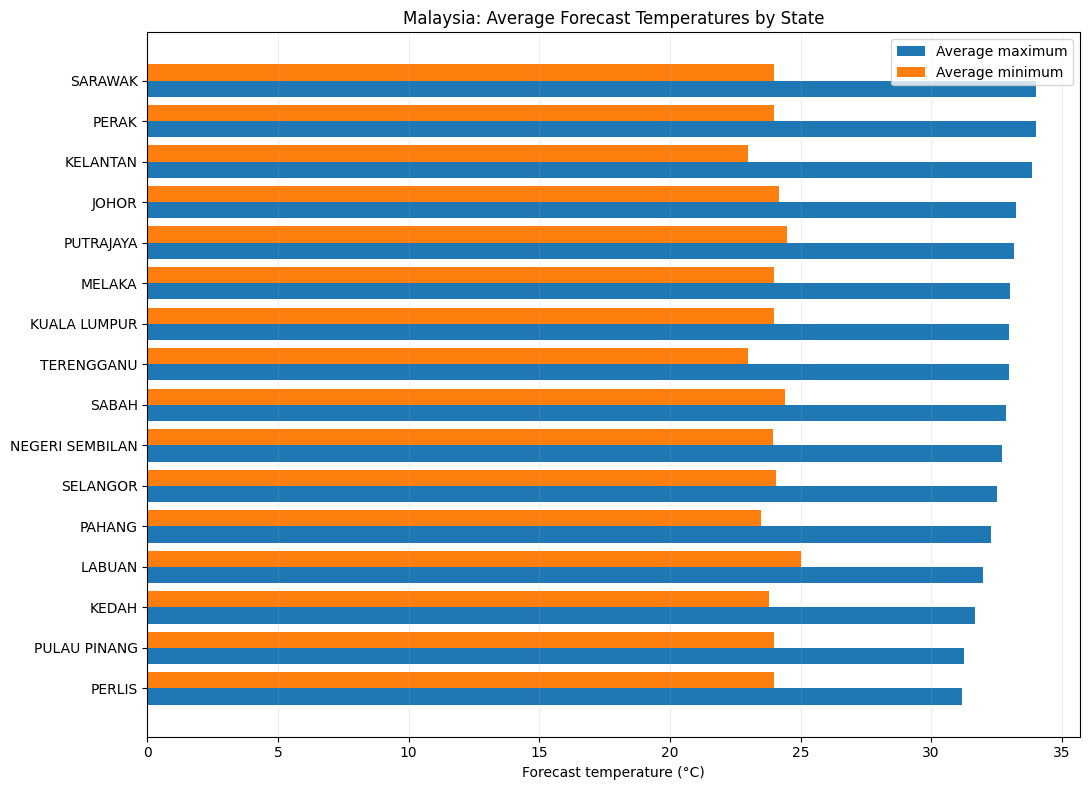

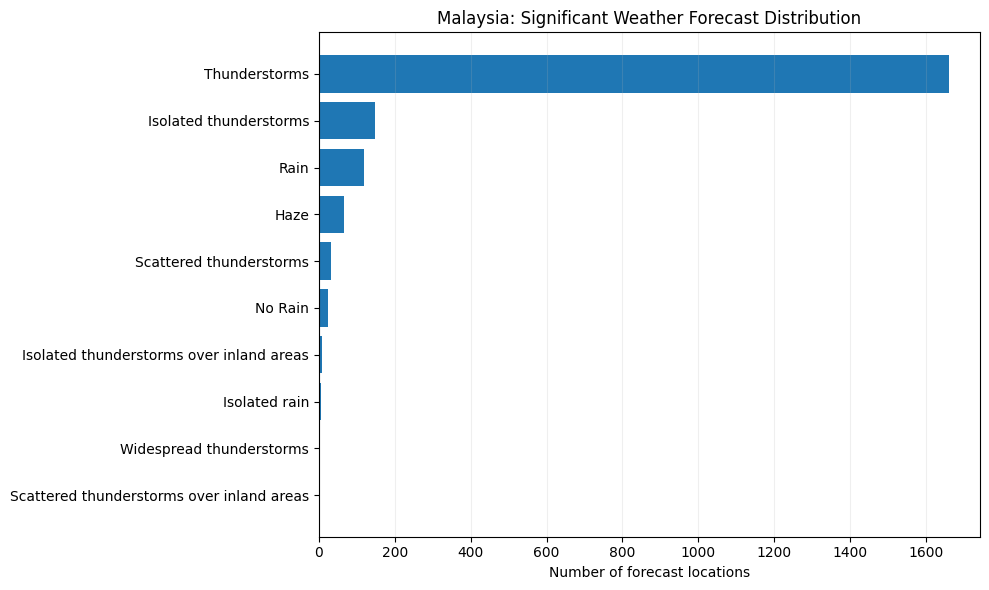

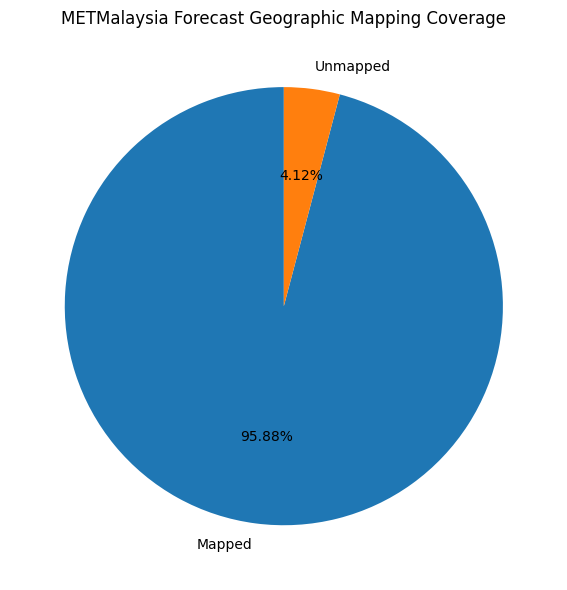


AUTOMATED CHARTS GENERATED
- geographic_mapping_coverage.png
- significant_weather_distribution.png
- state_temperature_comparison.png

Total charts: 3


In [40]:

# ============================================================
# STAGE 9B — AUTOMATED REPORT VISUALISATIONS
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPORTS = Path(
    "/content/metmalaysia_outputs/automated_reports"
)

CHARTS = REPORTS / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOAD REPORTING DATA
# ------------------------------------------------------------

locations = pd.read_csv(
    REPORTS / "location_forecasts.csv"
)

states = pd.read_csv(
    REPORTS / "state_temperature_summary.csv"
)

# ------------------------------------------------------------
# 2. STATE TEMPERATURE COMPARISON
# ------------------------------------------------------------

state_plot = states[
    states["state_name"] != "Unmapped"
].sort_values("avg_max_temp_c")

fig, ax = plt.subplots(figsize=(11, 8))

y = range(len(state_plot))

ax.barh(
    y,
    state_plot["avg_max_temp_c"],
    height=0.4,
    label="Average maximum"
)

ax.barh(
    [i + 0.4 for i in y],
    state_plot["avg_min_temp_c"],
    height=0.4,
    label="Average minimum"
)

ax.set_yticks(
    [i + 0.2 for i in y]
)

ax.set_yticklabels(
    state_plot["state_name"]
)

ax.set_xlabel("Forecast temperature (°C)")
ax.set_title(
    "Malaysia: Average Forecast Temperatures by State"
)
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    CHARTS / "state_temperature_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 3. NATIONAL SIGNIFICANT WEATHER FREQUENCY
# ------------------------------------------------------------

weather_counts = (
    locations["FSIGW"]
    .fillna("Not specified")
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    weather_counts.index,
    weather_counts.values
)

ax.set_xlabel("Number of forecast locations")
ax.set_title(
    "Malaysia: Significant Weather Forecast Distribution"
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    CHARTS / "significant_weather_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. GEOGRAPHIC MAPPING COVERAGE
# ------------------------------------------------------------

unique_locations = locations[
    ["locationid", "state_name"]
].drop_duplicates(subset=["locationid"])

mapped_count = (
    unique_locations["state_name"] != "Unmapped"
).sum()

unmapped_count = (
    unique_locations["state_name"] == "Unmapped"
).sum()

fig, ax = plt.subplots(figsize=(7, 6))

ax.pie(
    [mapped_count, unmapped_count],
    labels=["Mapped", "Unmapped"],
    autopct="%1.2f%%",
    startangle=90
)

ax.set_title(
    "METMalaysia Forecast Geographic Mapping Coverage"
)

plt.tight_layout()

plt.savefig(
    CHARTS / "geographic_mapping_coverage.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 5. VERIFY SAVED CHARTS
# ------------------------------------------------------------

print("\nAUTOMATED CHARTS GENERATED")

for file in sorted(CHARTS.glob("*.png")):
    print("-", file.name)

print("\nTotal charts:", len(list(CHARTS.glob("*.png"))))



# 📄 Stage 9C — Automated PDF Reporting

## Objective
Convert validated METMalaysia forecast summaries and
visualisations into a stakeholder-ready PDF report.

## Reporting Workflow
1. Load generated analytical summaries.
2. Retrieve saved forecast visualisations.
3. Calculate key reporting indicators.
4. Assemble a structured PDF document.
5. Save the PDF to the reporting directory.

## Expected Deliverable
`malaysia_weather_forecast_report.pdf`

## Business Value
Transforms API data into a repeatable reporting
deliverable that can be shared without requiring
stakeholders to execute Python notebooks.

## Limitations
- Forecast values are not observed weather.
- Geographic mapping is approximately 95.88% complete
  for the current dataset.
- State assignments follow the API hierarchy.
- The report reflects the collected forecast snapshot.
- Scheduling and email delivery are not yet enabled.


In [41]:

%pip -q install reportlab


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 23.0 MB/s eta 0:00:00


In [42]:

# ============================================================
# STAGE 9C — AUTOMATED PDF WEATHER REPORT
# ============================================================

from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from xml.sax.saxutils import escape

import pandas as pd

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak,
    KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4

# ------------------------------------------------------------
# 1. PATHS AND INPUTS
# ------------------------------------------------------------

BASE = Path("/content/metmalaysia_outputs")
REPORTS = BASE / "automated_reports"
CHARTS = REPORTS / "charts"

pdf_path = REPORTS / "malaysia_weather_forecast_report.pdf"

required_files = [
    REPORTS / "location_forecasts.csv",
    REPORTS / "state_temperature_summary.csv",
    CHARTS / "state_temperature_comparison.png",
    CHARTS / "significant_weather_distribution.png",
    CHARTS / "geographic_mapping_coverage.png"
]

missing_files = [
    str(path) for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing reporting files:\n" +
        "\n".join(missing_files)
    )

locations = pd.read_csv(required_files[0])
states = pd.read_csv(required_files[1])

# ------------------------------------------------------------
# 2. DERIVE REPORT INDICATORS
# ------------------------------------------------------------

for col in ["FMAXT", "FMINT"]:
    locations[col] = pd.to_numeric(
        locations[col], errors="coerce"
    )

if locations[["FMAXT", "FMINT"]].isna().any().any():
    raise ValueError("Invalid temperature values.")

unique_locations = locations.drop_duplicates(
    subset=["locationid"]
)

total_locations = len(unique_locations)

mapped_locations = (
    unique_locations["state_name"] != "Unmapped"
).sum()

mapping_pct = (
    mapped_locations / total_locations * 100
    if total_locations else 0
)

avg_max = locations["FMAXT"].mean()
avg_min = locations["FMINT"].mean()

weather_counts = (
    locations["FSIGW"]
    .fillna("Not specified")
    .value_counts()
)

top_weather = (
    str(weather_counts.index[0])
    if not weather_counts.empty else "Unavailable"
)

forecast_dates = sorted(
    pd.to_datetime(locations["date"], utc=True)
    .dt.strftime("%Y-%m-%d")
    .unique()
)

date_label = ", ".join(forecast_dates)

generated_at = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).strftime("%d %B %Y, %I:%M %p MYT")

# ------------------------------------------------------------
# 3. PDF STYLES
# ------------------------------------------------------------

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=22,
    leading=28,
    textColor=colors.HexColor("#17324D"),
    spaceAfter=18
))

styles.add(ParagraphStyle(
    name="ReportSection",
    parent=styles["Heading2"],
    fontSize=13,
    leading=17,
    textColor=colors.HexColor("#17324D"),
    spaceBefore=14,
    spaceAfter=9
))

styles.add(ParagraphStyle(
    name="ReportBody",
    parent=styles["BodyText"],
    fontSize=9,
    leading=14,
    spaceAfter=9
))

styles.add(ParagraphStyle(
    name="ReportSmall",
    parent=styles["BodyText"],
    fontSize=8,
    leading=11
))

# ------------------------------------------------------------
# 4. DOCUMENT CONFIGURATION
# ------------------------------------------------------------

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=42,
    leftMargin=42,
    topMargin=48,
    bottomMargin=48
)

story = []

def add_heading(text):
    story.append(
        Paragraph(text, styles["ReportSection"])
    )

def add_body(text):
    story.append(
        Paragraph(text, styles["ReportBody"])
    )

def add_chart(path, width=6.7 * inch):
    from reportlab.lib.utils import ImageReader

    image_reader = ImageReader(str(path))
    img_width, img_height = image_reader.getSize()

    height = width * img_height / img_width

    # Fit images within the printable page height
    max_height = 8.2 * inch

    if height > max_height:
        scale = max_height / height
        width *= scale
        height *= scale

    story.append(
        Image(str(path), width=width, height=height)
    )

def add_table(data, widths=None):
    table = Table(
        data,
        colWidths=widths,
        repeatRows=1,
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0),
         colors.HexColor("#17324D")),
        ("TEXTCOLOR", (0, 0), (-1, 0),
         colors.white),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#EDF3F7")]),
        ("GRID", (0, 0), (-1, -1),
         0.25, colors.HexColor("#D6DFE5")),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
        ("TOPPADDING", (0, 0), (-1, -1), 7),
    ]))

    story.append(table)

# ------------------------------------------------------------
# 5. TITLE AND EXECUTIVE SUMMARY
# ------------------------------------------------------------

story.append(Paragraph(
    "METMalaysia Weather Forecast Report",
    styles["ReportTitle"]
))

add_body(
    f"<b>Forecast date(s):</b> {escape(date_label)}"
)

add_body(
    f"<b>Report generated:</b> {escape(generated_at)}"
)

add_body(
    "<b>Source:</b> METMalaysia General Forecast API"
)

add_heading("Executive Summary")

add_body(
    f"This report summarises published forecasts for "
    f"{total_locations:,} locations across Malaysia. "
    f"The average forecast daily maximum temperature "
    f"is {avg_max:.2f} °C, while the average forecast "
    f"daily minimum temperature is {avg_min:.2f} °C. "
    f"The most frequently reported significant-weather "
    f"category is {escape(top_weather)}."
)

add_body(
    f"Geographic state mapping covers "
    f"{mapped_locations:,} of {total_locations:,} "
    f"forecast locations ({mapping_pct:.2f}%). "
    f"Locations without resolved state assignments "
    f"remain included in national statistics."
)

# ------------------------------------------------------------
# 6. NATIONAL SUMMARY TABLE
# ------------------------------------------------------------

add_heading("National Forecast Overview")

summary_data = [
    ["Indicator", "Value"],
    ["Forecast locations", f"{total_locations:,}"],
    ["Mapped locations", f"{mapped_locations:,}"],
    ["Geographic coverage", f"{mapping_pct:.2f}%"],
    ["Average maximum temperature", f"{avg_max:.2f} °C"],
    ["Average minimum temperature", f"{avg_min:.2f} °C"],
    ["Most frequent weather category", top_weather],
]

add_table(summary_data, [3.3 * inch, 3.2 * inch])

# ------------------------------------------------------------
# 7. STATE-LEVEL SUMMARY
# ------------------------------------------------------------

story.append(PageBreak())
add_heading("State-Level Temperature Comparison")

state_table = [[
    "State / Territory", "Locations",
    "Avg Max (°C)", "Avg Min (°C)"
]]

for _, row in states.iterrows():
    state_table.append([
        str(row["state_name"]),
        str(int(row["locations"])),
        f"{row['avg_max_temp_c']:.2f}",
        f"{row['avg_min_temp_c']:.2f}"
    ])

add_table(
    state_table,
    [2.35 * inch, 1.1 * inch, 1.5 * inch, 1.5 * inch]
)

story.append(Spacer(1, 12))
add_chart(
    CHARTS / "state_temperature_comparison.png"
)

# ------------------------------------------------------------
# 8. WEATHER CATEGORY CHART
# ------------------------------------------------------------

story.append(PageBreak())
add_heading("Significant Weather Forecast Distribution")

add_body(
    "The following chart counts forecast locations "
    "by their published significant-weather category. "
    "These are forecast classifications, not observed "
    "weather events."
)

add_chart(
    CHARTS / "significant_weather_distribution.png"
)

# ------------------------------------------------------------
# 9. GEOGRAPHIC COVERAGE CHART
# ------------------------------------------------------------

story.append(PageBreak())
add_heading("Geographic Mapping Coverage")

add_chart(
    CHARTS / "geographic_mapping_coverage.png"
)

# ------------------------------------------------------------
# 10. METHODOLOGY AND LIMITATIONS
# ------------------------------------------------------------

add_heading("Methodology")

add_body(
    "Forecast records were retrieved through the "
    "METMalaysia API, validated, transformed into "
    "location-level tables and aggregated for reporting."
)

add_heading("Limitations")

add_body(
    "Forecast values are not observed temperatures. "
    "National and state temperature averages are "
    "unweighted across forecast locations. "
    "State assignments follow the METMalaysia location "
    "hierarchy and are not independently verified "
    "administrative boundaries. Unmapped locations "
    "are retained in national calculations. "
    "This report represents the saved forecast snapshot "
    "and is not a continuously updated live report."
)

# ------------------------------------------------------------
# 11. PAGE NUMBERS
# ------------------------------------------------------------

def add_page_number(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawRightString(
        A4[0] - 42,
        25,
        f"Page {document.page}"
    )
    canvas.restoreState()

# ------------------------------------------------------------
# 12. BUILD PDF
# ------------------------------------------------------------

doc.build(
    story,
    onFirstPage=add_page_number,
    onLaterPages=add_page_number
)

print("PDF report generated successfully!")
print("Saved to:", pdf_path)
print("File size:", round(
    pdf_path.stat().st_size / 1024, 2
), "KB")


PDF report generated successfully!
Saved to: /content/metmalaysia_outputs/automated_reports/malaysia_weather_forecast_report.pdf
File size: 240.58 KB


In [43]:

# ============================================================
# STAGE 10A — EMAIL METMALAYSIA WEATHER REPORT
# ============================================================

import smtplib
import ssl
import getpass
from pathlib import Path
from email.message import EmailMessage
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd

# ------------------------------------------------------------
# 1. EMAIL CONFIGURATION
# ------------------------------------------------------------

sender_email = input("Your Gmail address: ").strip()
receiver_email = input("Recipient email address: ").strip()

# Input is hidden and is not printed in notebook output
app_password = getpass.getpass(
    "Enter your Gmail App Password: "
).replace(" ", "")

# ------------------------------------------------------------
# 2. VERIFY REPORT FILES
# ------------------------------------------------------------

REPORTS = Path(
    "/content/metmalaysia_outputs/automated_reports"
)

pdf_path = REPORTS / "malaysia_weather_forecast_report.pdf"
csv_path = REPORTS / "state_temperature_summary.csv"
location_path = REPORTS / "location_forecasts.csv"

for file_path in [pdf_path, csv_path, location_path]:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required report missing: {file_path}"
        )

# ------------------------------------------------------------
# 3. PREPARE EMAIL SUMMARY
# ------------------------------------------------------------

locations = pd.read_csv(location_path)

forecast_dates = sorted(
    pd.to_datetime(
        locations["date"],
        utc=True
    ).dt.strftime("%Y-%m-%d").unique()
)

forecast_date_text = ", ".join(forecast_dates)

location_count = locations["locationid"].nunique()

mapped_count = locations.loc[
    locations["state_name"] != "Unmapped",
    "locationid"
].nunique()

coverage = 100 * mapped_count / location_count

generated_at = datetime.now(
    ZoneInfo("Asia/Kuala_Lumpur")
).strftime("%d %B %Y, %I:%M %p MYT")

# ------------------------------------------------------------
# 4. BUILD EMAIL
# ------------------------------------------------------------

message = EmailMessage()

message["From"] = sender_email
message["To"] = receiver_email
message["Subject"] = (
    f"METMalaysia Weather Forecast Report | "
    f"{forecast_date_text}"
)

message.set_content(f"""
Hello,

Please find attached the automated METMalaysia
Weather Forecast Report.

FORECAST SUMMARY
----------------
Forecast date(s): {forecast_date_text}
Forecast locations: {location_count:,}
Mapped locations: {mapped_count:,}
Geographic coverage: {coverage:.2f}%

Report generated: {generated_at}

The report includes:
- National weather forecast statistics
- State-level temperature comparisons
- Significant weather analysis
- Geographic mapping coverage
- Methodology and limitations

Note:
This report contains forecast data, not observed
weather measurements. Geographic assignments
follow the METMalaysia API location hierarchy.

Regards,
METMalaysia Weather Reporting Pipeline
""".strip())

# ------------------------------------------------------------
# 5. ATTACH PDF AND CSV
# ------------------------------------------------------------

attachments = [
    (pdf_path, "application", "pdf"),
    (csv_path, "text", "csv")
]

for file_path, main_type, sub_type in attachments:

    with open(file_path, "rb") as f:
        message.add_attachment(
            f.read(),
            maintype=main_type,
            subtype=sub_type,
            filename=file_path.name
        )

# ------------------------------------------------------------
# 6. PREVIEW BEFORE SENDING
# ------------------------------------------------------------

print("\nEMAIL PREVIEW")
print("From:", sender_email)
print("To:", receiver_email)
print("Subject:", message["Subject"])
print("Attachments:", [f[0].name for f in attachments])

confirmation = input(
    "\nType SEND to email the report: "
).strip()

if confirmation != "SEND":
    print("Email cancelled.")
else:
    # --------------------------------------------------------
    # 7. SEND VIA GMAIL SMTP
    # --------------------------------------------------------

    context = ssl.create_default_context()

    with smtplib.SMTP_SSL(
        "smtp.gmail.com",
        465,
        context=context,
        timeout=30
    ) as server:

        server.login(sender_email, app_password)
        server.send_message(message)

    print("\nEmail submitted successfully via Gmail SMTP!")
    print("Recipient:", receiver_email)


Your Gmail address: nuruldalia01@gmail.com
Recipient email address: nuruldalia01@gmail.com
Enter your Gmail App Password: ··········

EMAIL PREVIEW
From: nuruldalia01@gmail.com
To: nuruldalia01@gmail.com
Subject: METMalaysia Weather Forecast Report | 2026-10-18
Attachments: ['malaysia_weather_forecast_report.pdf', 'state_temperature_summary.csv']

Type SEND to email the report: SEND

Email submitted successfully via Gmail SMTP!
Recipient: nuruldalia01@gmail.com
